This notebook contains the code to generate Figure 3 of "Wasting is essential: cachexia is caused by a prolonged wound healing mechanism" and an explanation of the figure

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from reaction_flask import ReactionFlask

In [2]:
inflammationParameters = [20, 40, 60]
numPointsToTest = 20

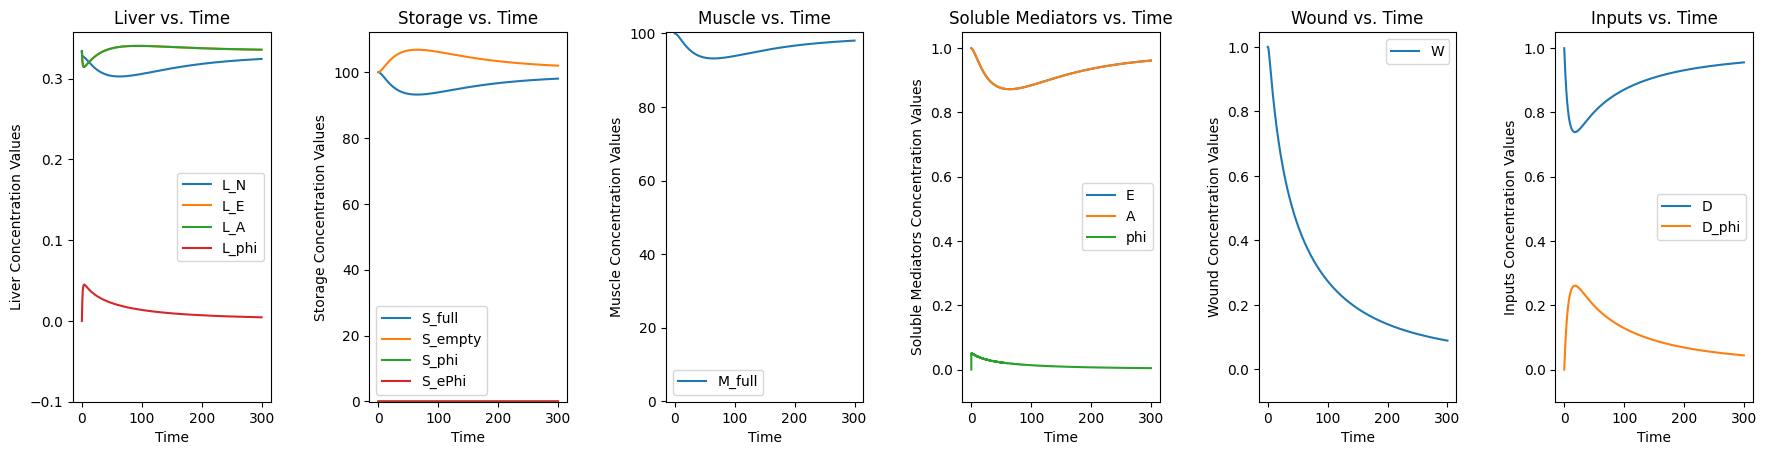

-1.0257633912751563
Final value of W: 0.08932078900442045


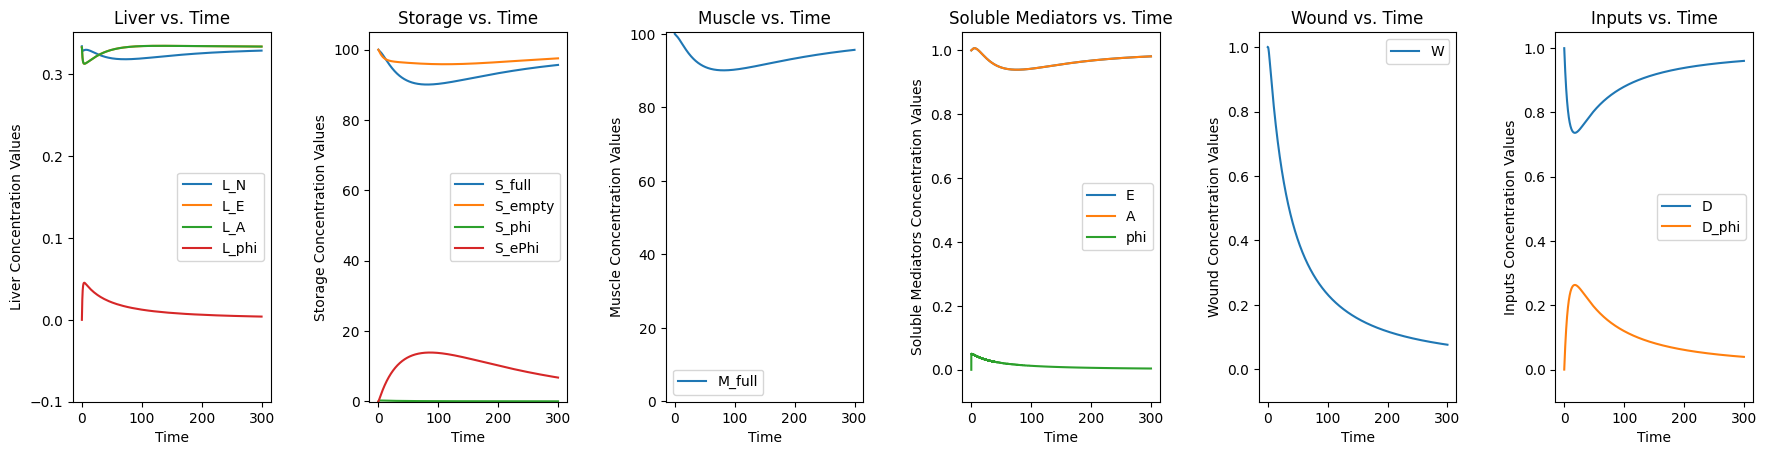

-0.9585874945020688
Final value of W: 0.07676961017284516


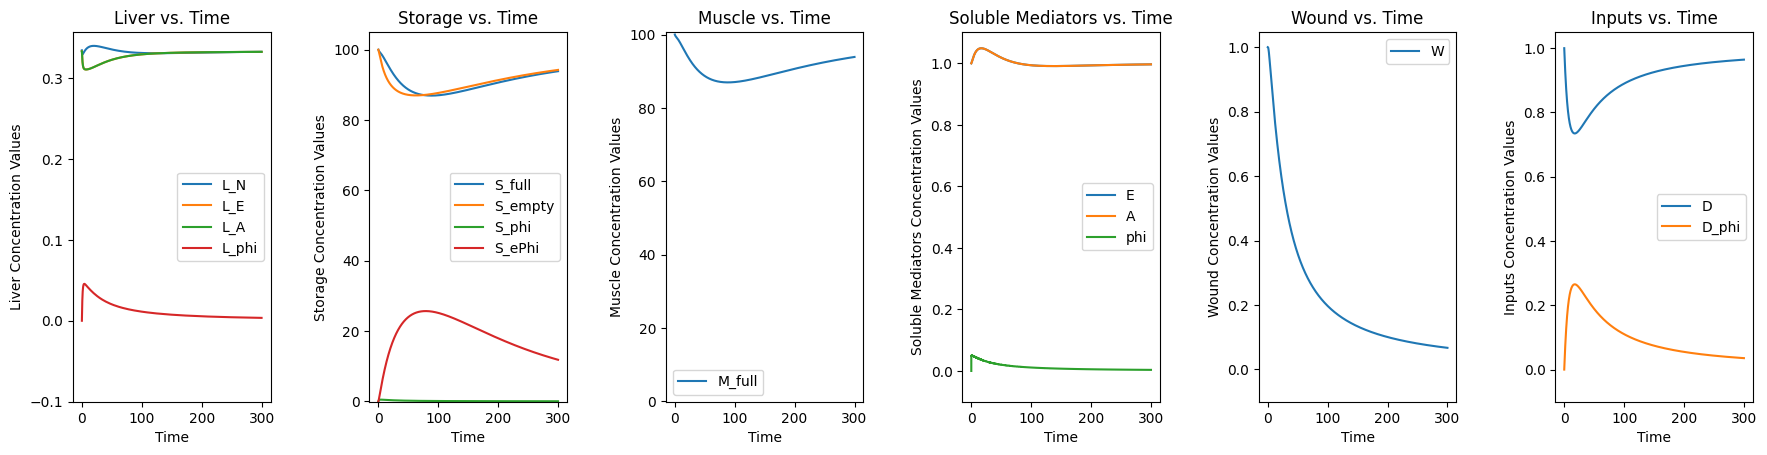

-0.8901891465015955
Final value of W: 0.06719100594062544


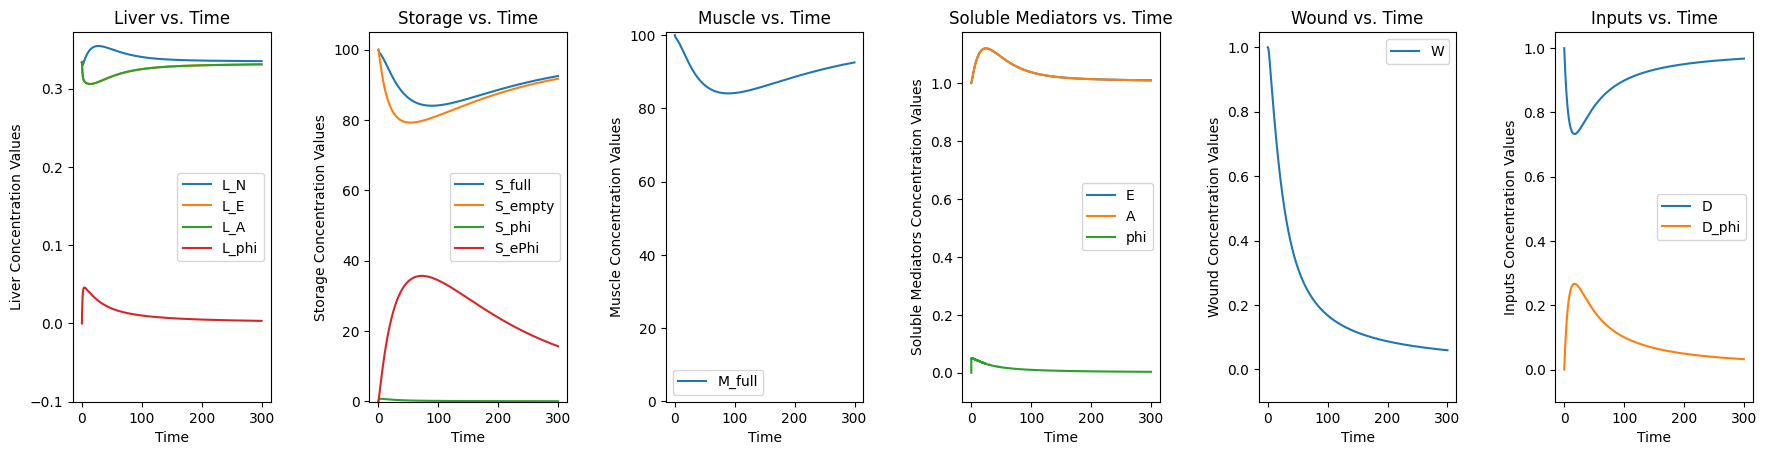

-0.8275484033998053
Final value of W: 0.05976045961562784


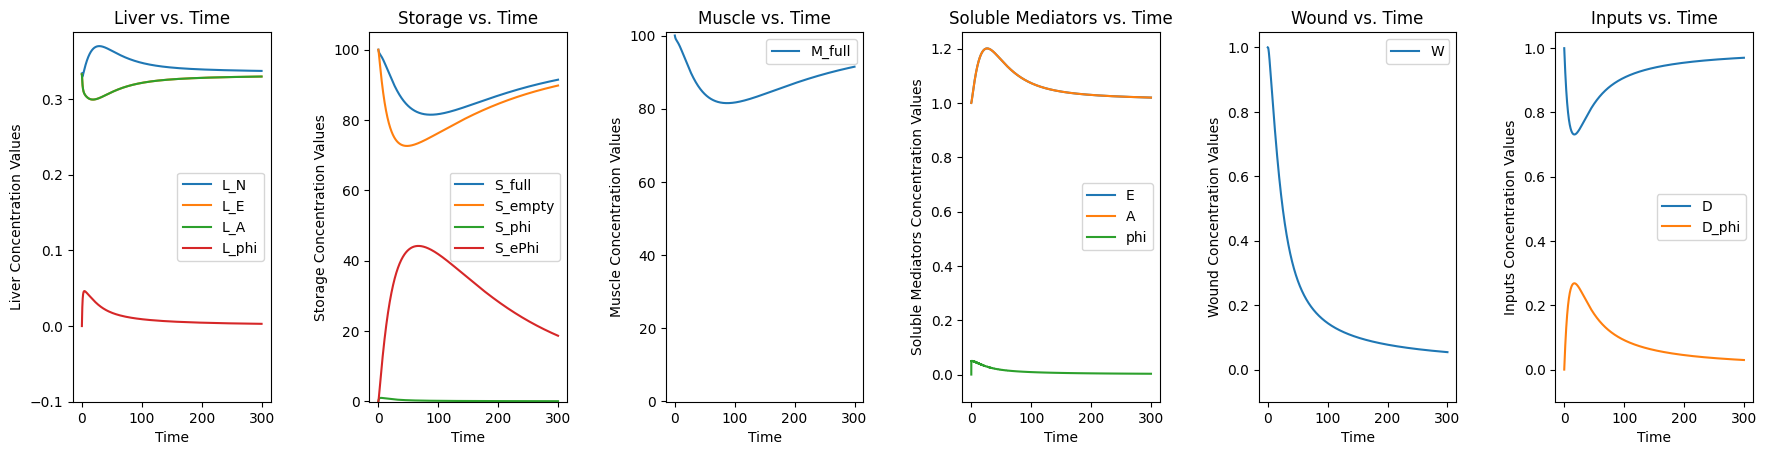

-0.7721059193874534
Final value of W: 0.053891940822855415


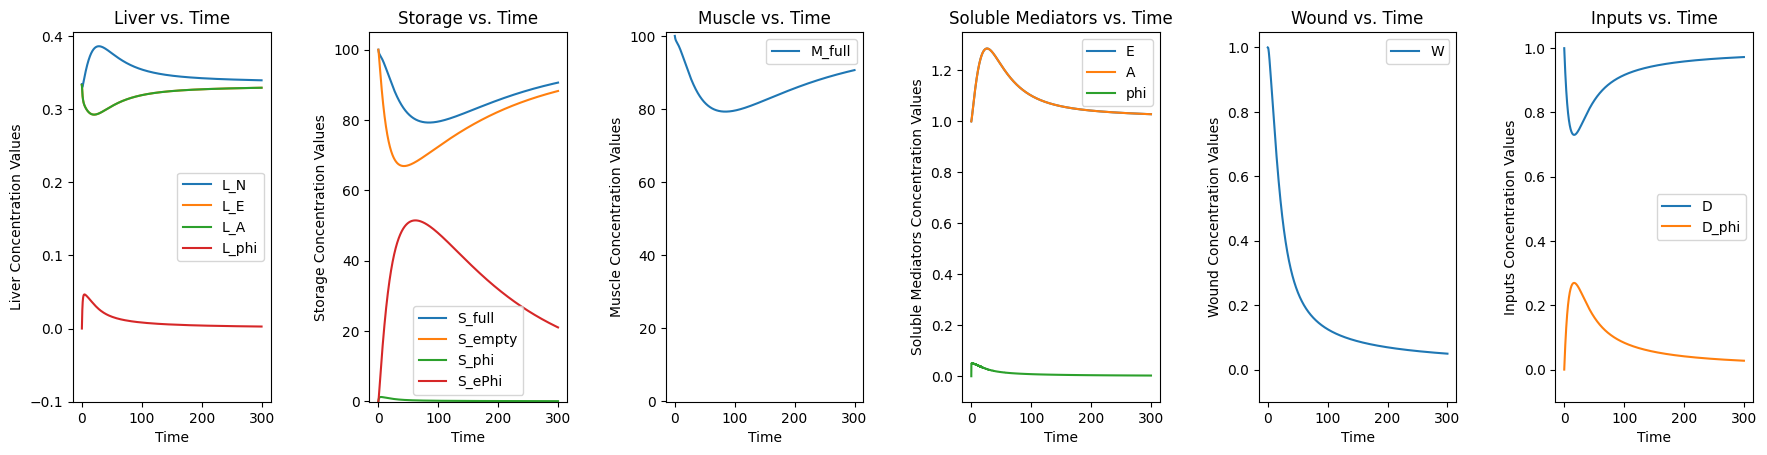

-0.7235565346964559
Final value of W: 0.04917333885424016


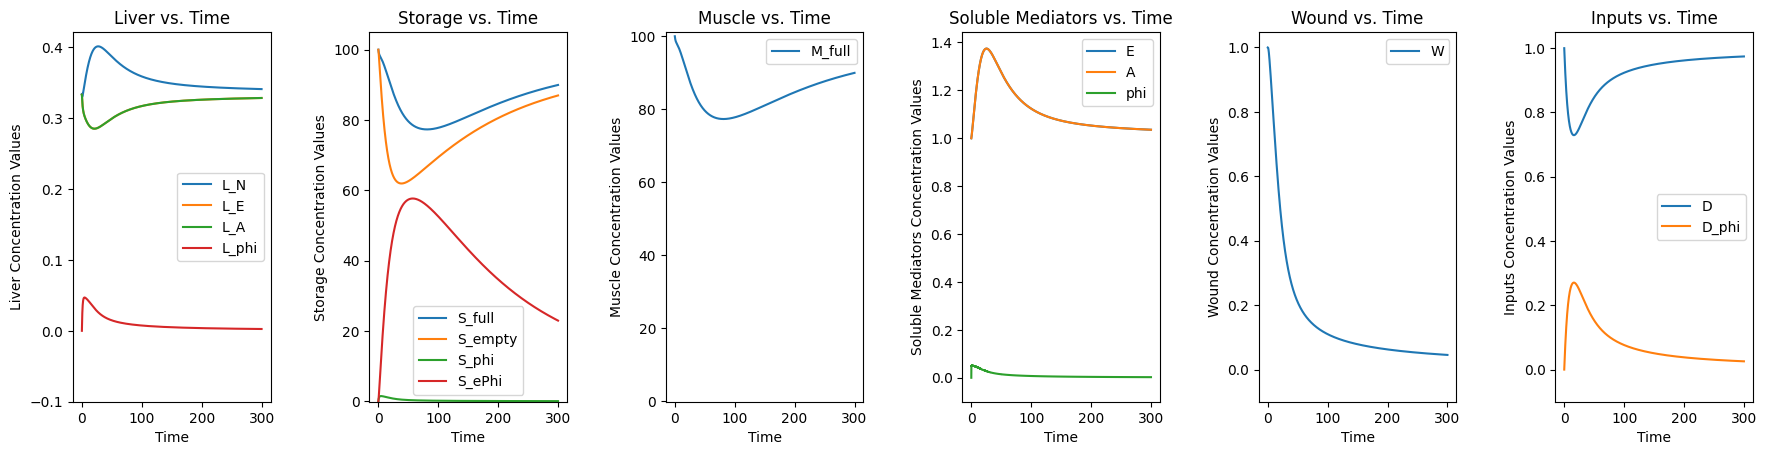

-0.6811652025081198
Final value of W: 0.045314177100225256


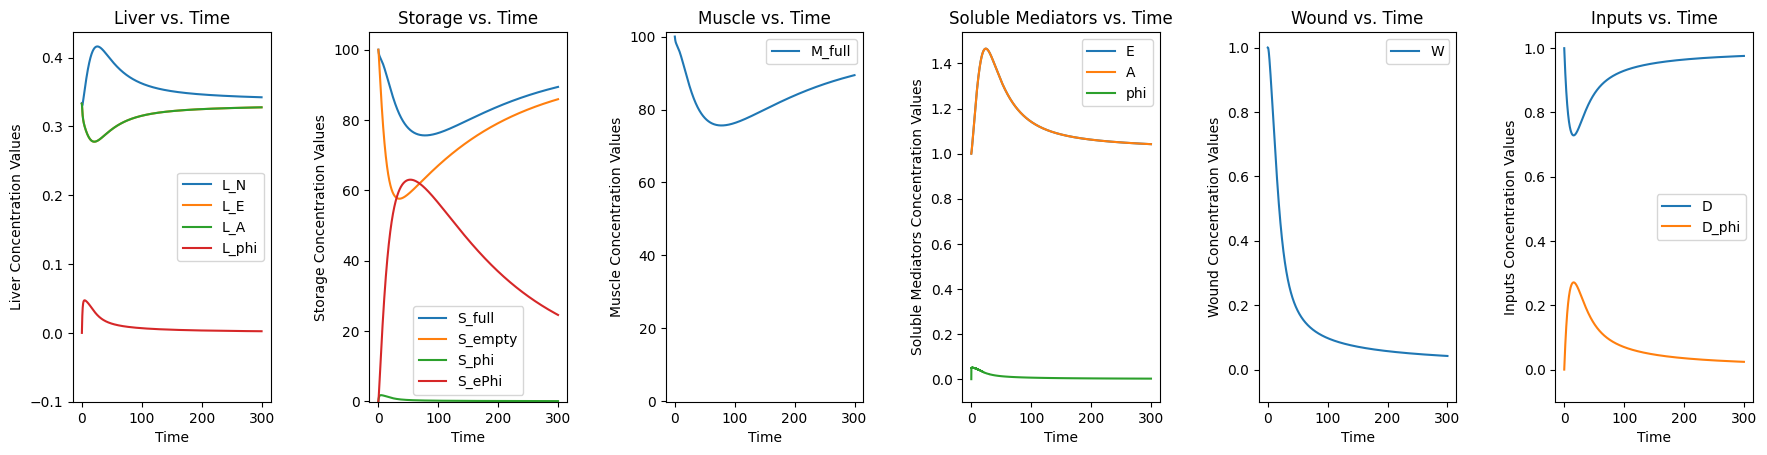

-0.6441389030329081
Final value of W: 0.042107781717294526


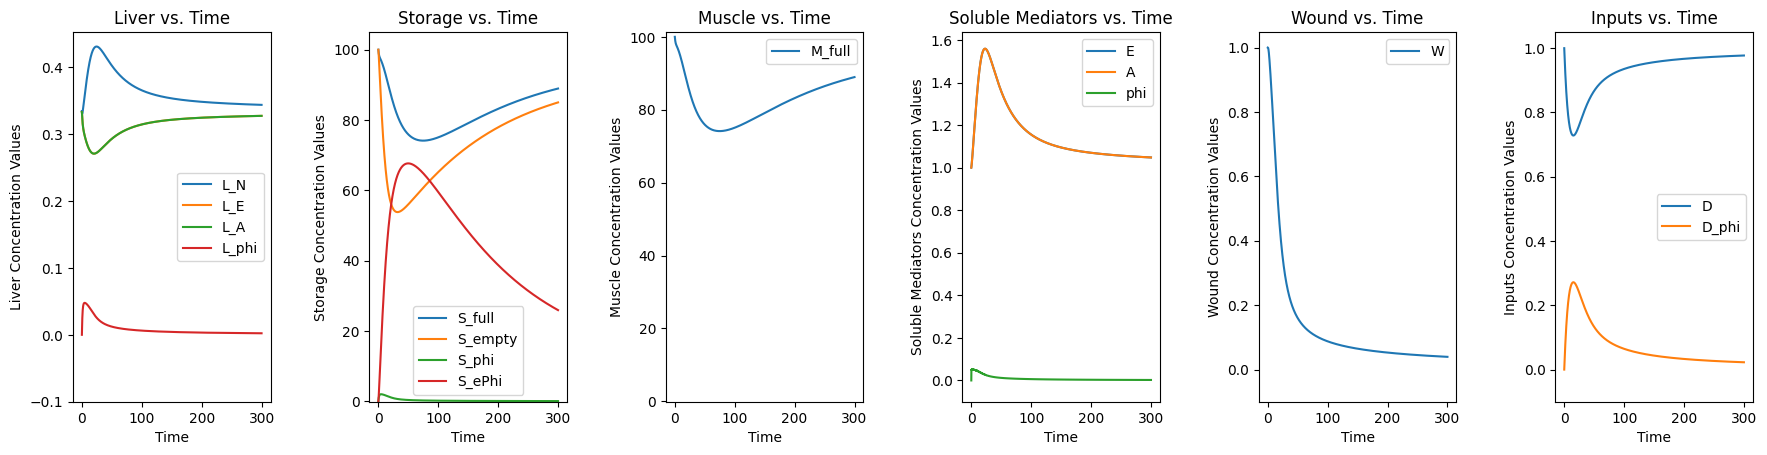

-0.6117401806805849
Final value of W: 0.03940517502798035


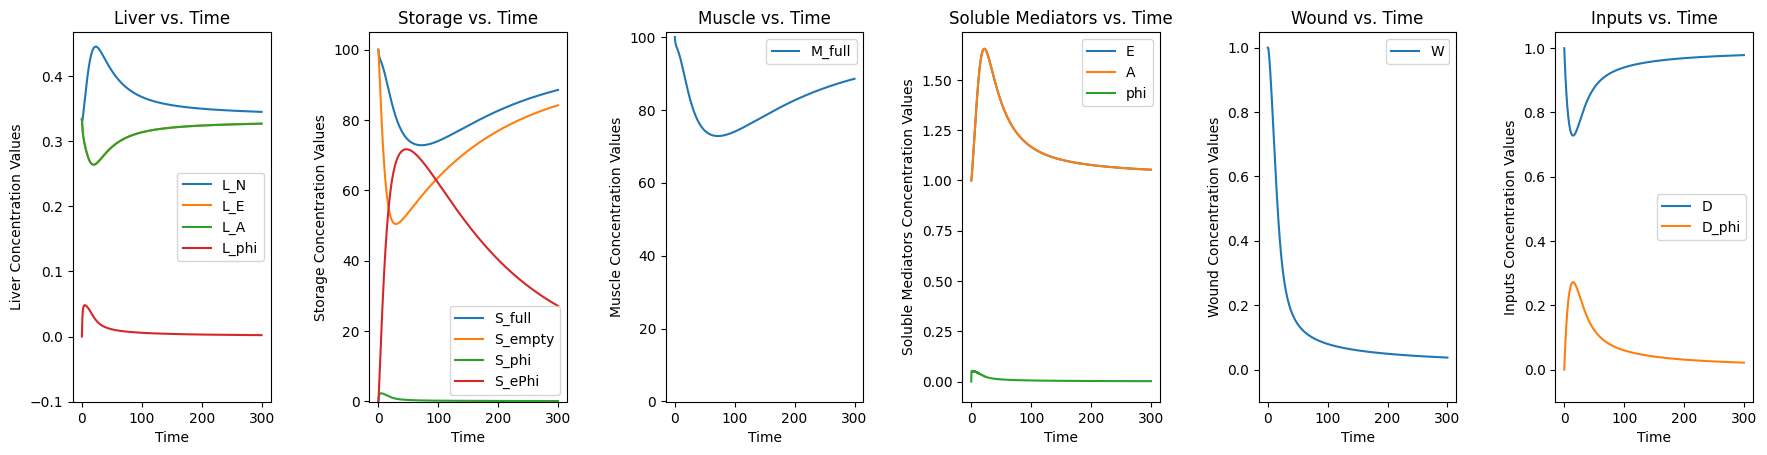

-0.5833193224861175
Final value of W: 0.037097378830386316


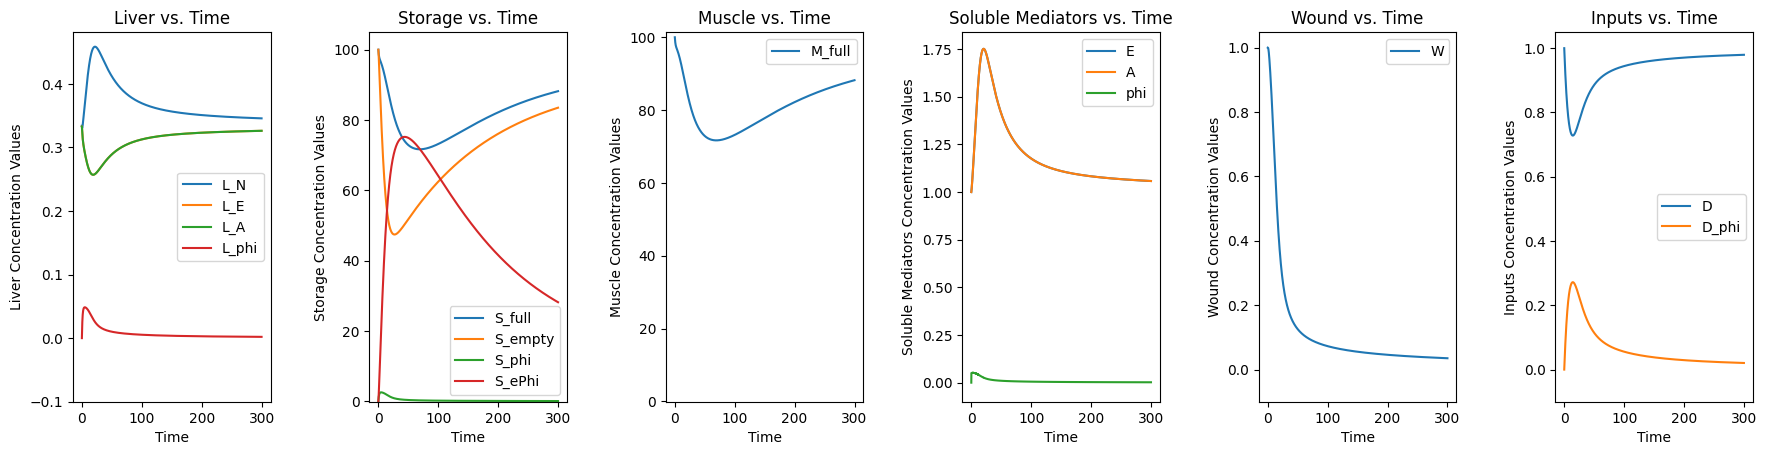

-0.5583185395547656
Final value of W: 0.03510345178895682


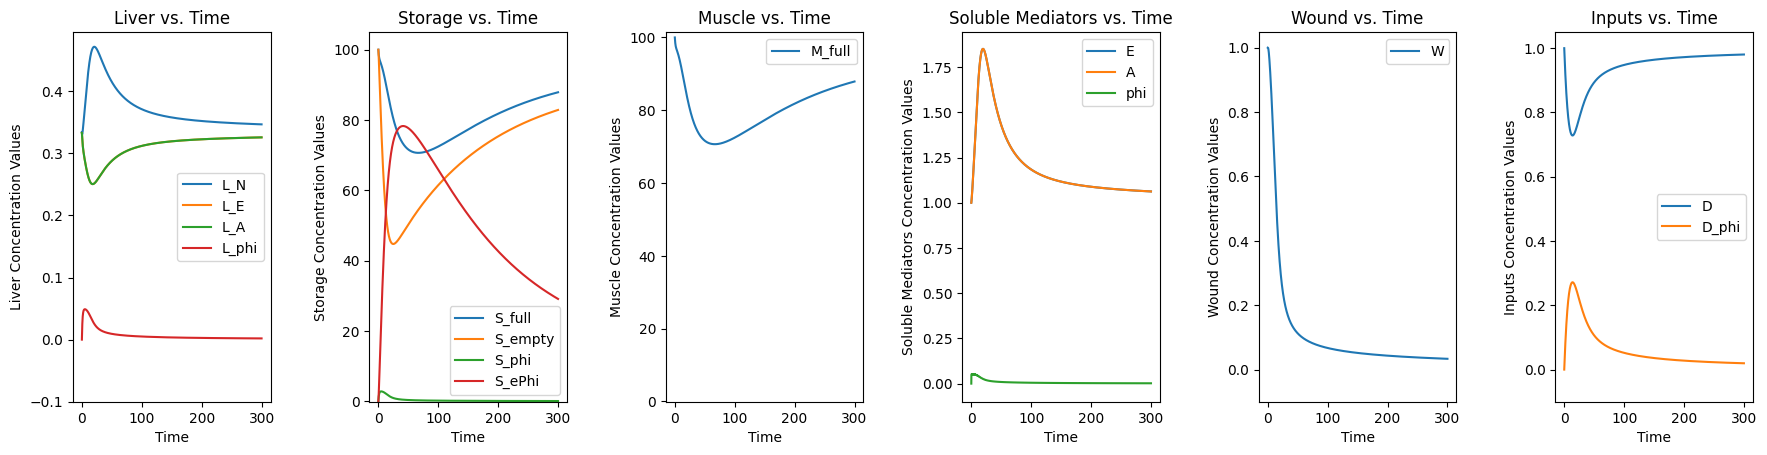

-0.5362646232039073
Final value of W: 0.033362359726437786


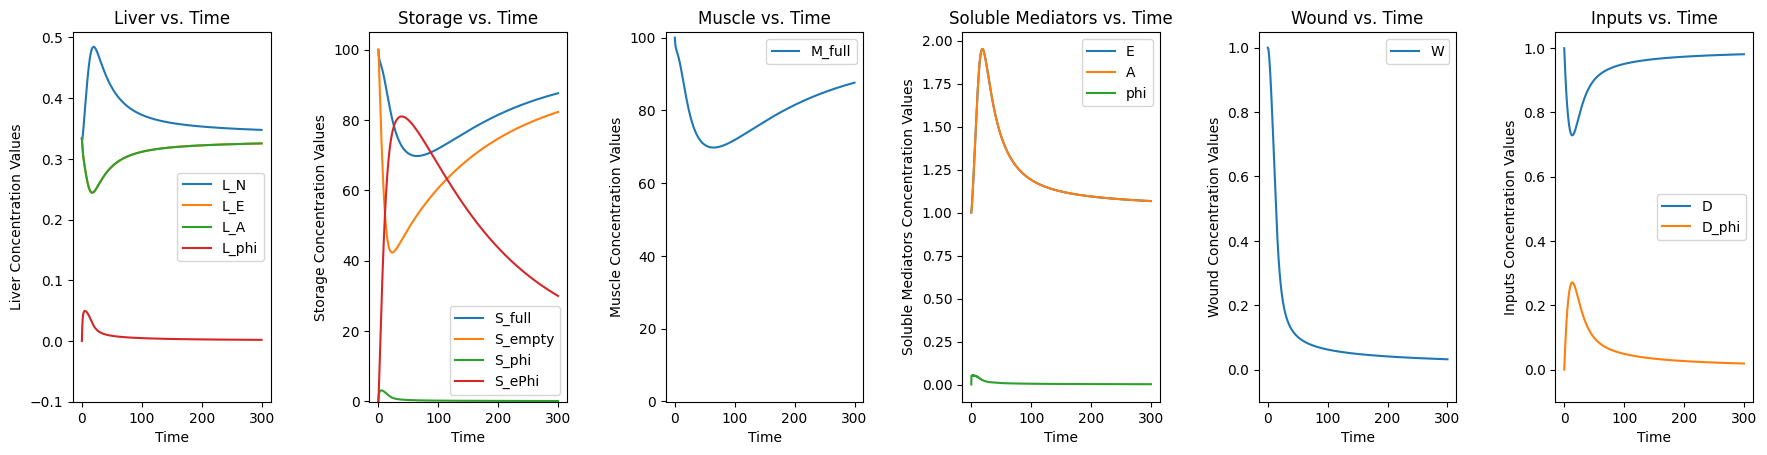

-0.5167592254602201
Final value of W: 0.031827396592292743


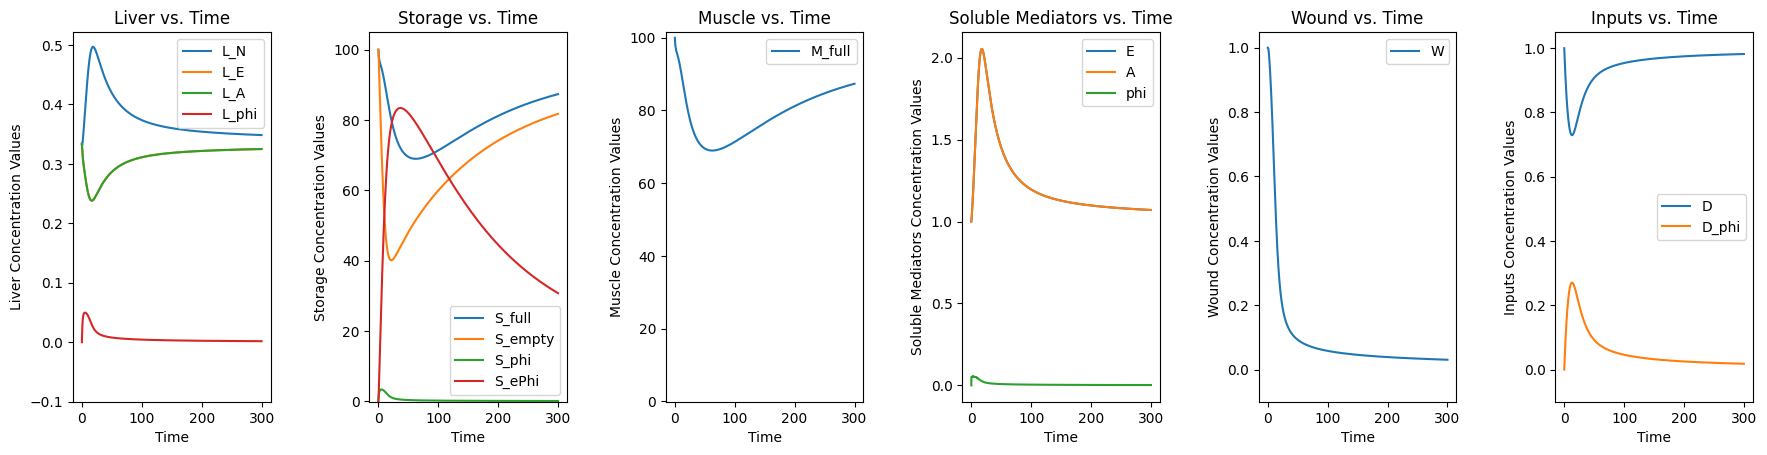

-0.4994675341344599
Final value of W: 0.030462309152699697


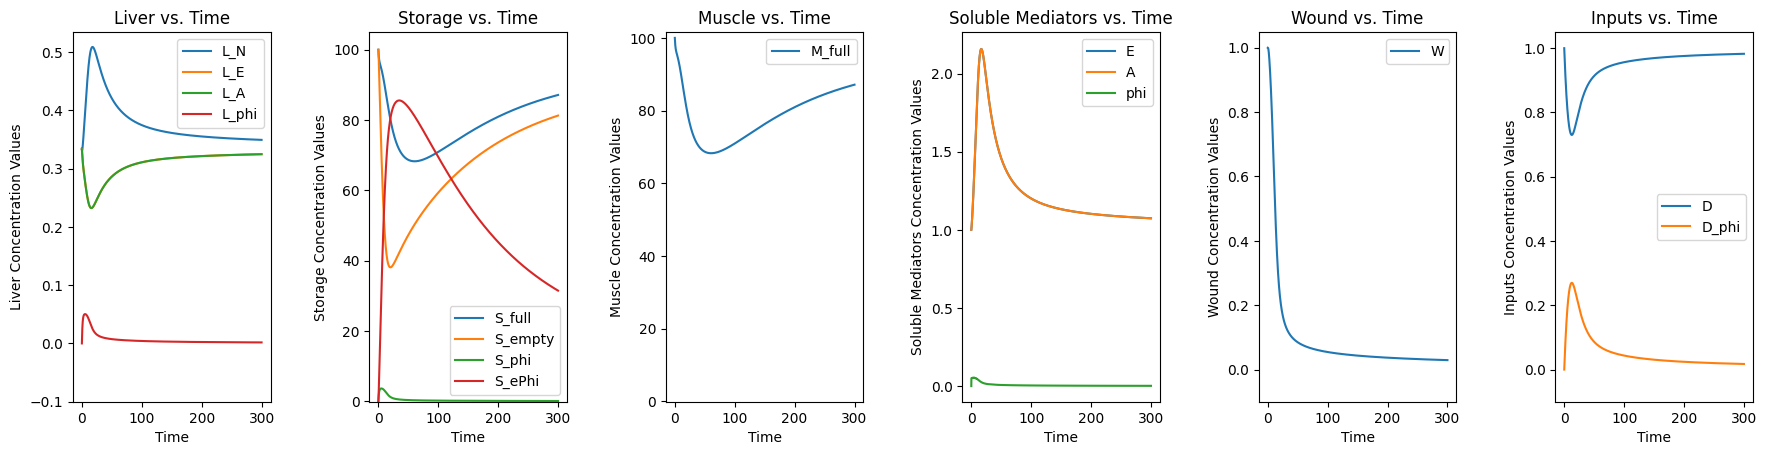

-0.48410885922509117
Final value of W: 0.029238568991775907


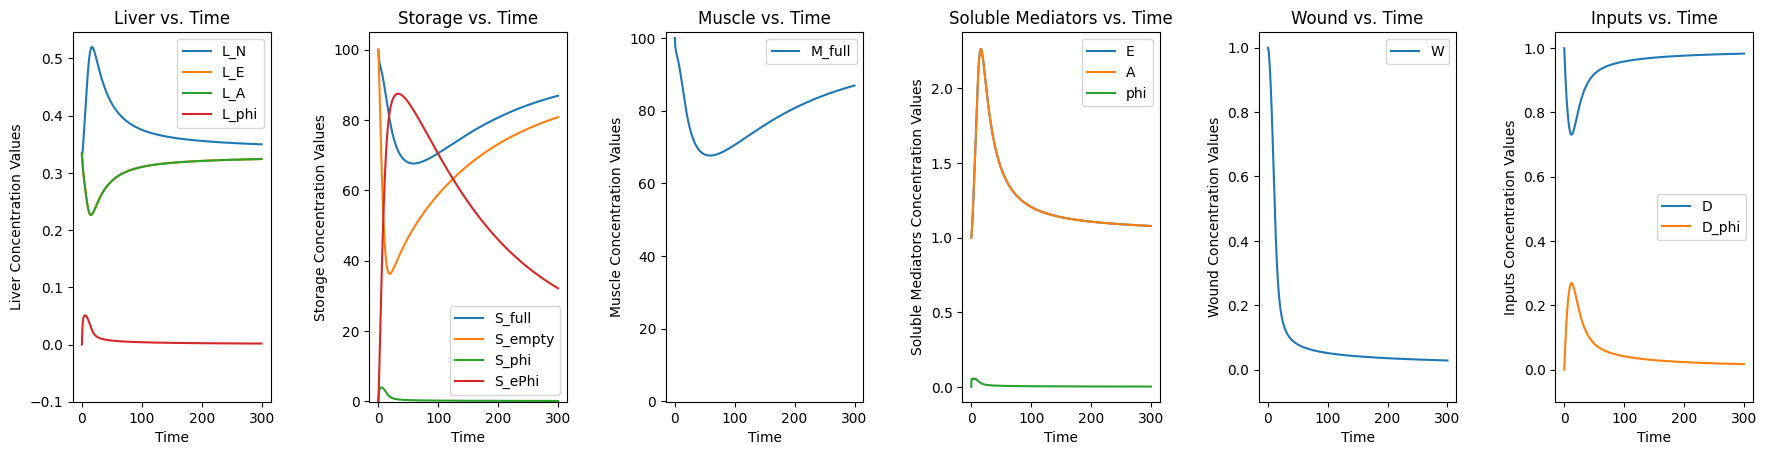

-0.470447400373629
Final value of W: 0.0281334252610603


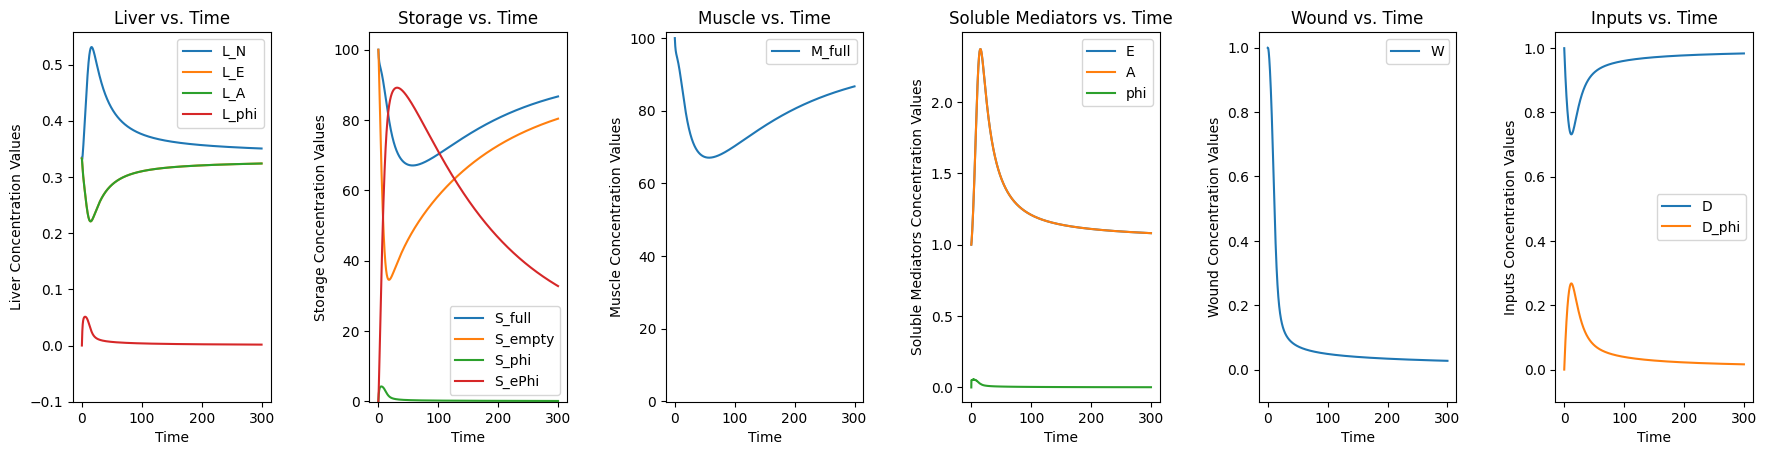

-0.45828530883744356
Final value of W: 0.027128494896685947


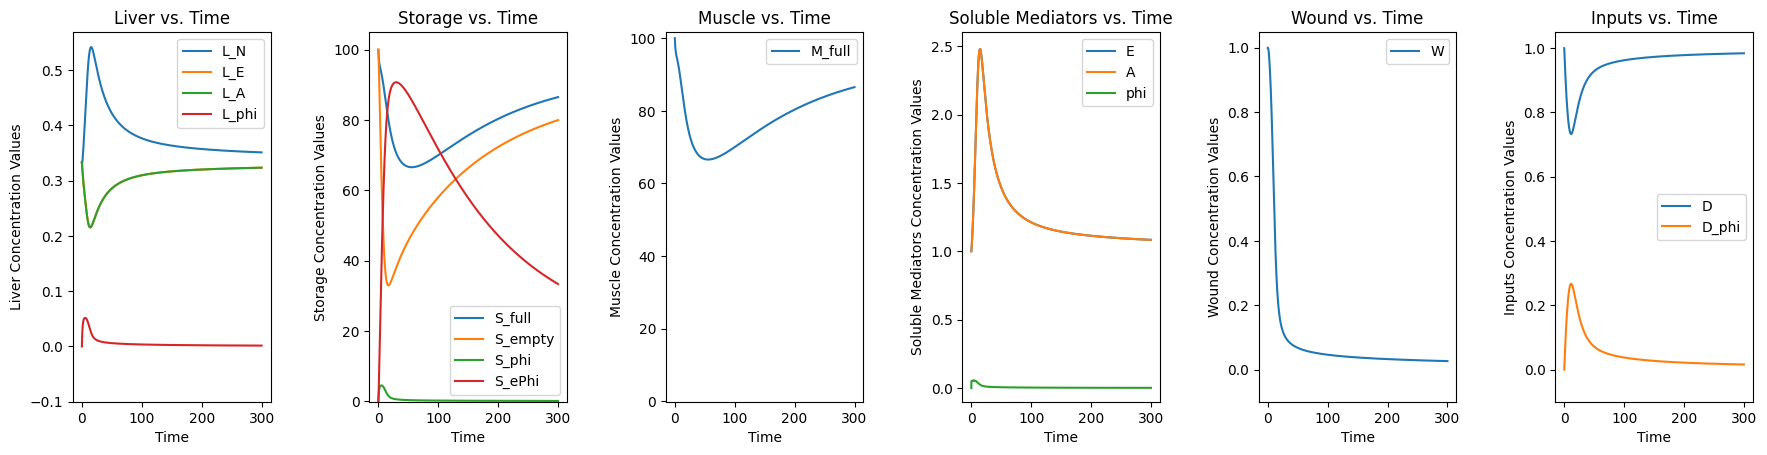

-0.4474554442889593
Final value of W: 0.0262087272337321


KeyboardInterrupt: 

In [ ]:
initWound = 1

diet = 1

woundValsVsTime = []

rxnFlask = ReactionFlask(['W', 'D', 'D_phi', 'L_N', 'L_E', 'L_A', 'L_phi', 'S_full', 'S_empty', 'S_phi', 'S_ePhi', 'M_full', 'M_empty', 'M_phi', 'M_ePhi', 'E', 'A', 'phi', 'pI'], components = {"Liver" : ['L_N', 'L_E', 'L_A', 'L_phi'], "Storage" : ['S_full', 'S_empty', 'S_phi', 'S_ePhi'], "Muscle" : ['M_full'], "Soluble Mediators" : ['E', 'A', 'phi'], "Wound" : ['W'], "Inputs" : ['D', 'D_phi']})

rxnFlask.setInitialCondition([initWound, diet, 0, 0.334, 0.333, 0.333, 0, 100, 100, 0, 0, 100, 100, 0, 0, 1, 1, 0, 0])

lowSimulationOutputs = []

rxnFlask.addReaction("Reaction 1: L_N -> L_A", 1, reactantsDict = {'L_N' : 1}, productsDict = {'L_A' : 1})

#
rxnFlask.addReaction("Reaction 2: L_A + A -> L_N", 1, reactantsDict = {'L_A' : 1, 'A' : 1}, productsDict = {'L_N' : 1, 'A': 1})

#
rxnFlask.addReaction("Reaction 3: L_A + E -> L_A + A", 1, reactantsDict = {'L_A' : 1, 'E' : 1}, productsDict = {'L_A' : 1, 'A' : 1})

#
rxnFlask.addReaction("Reaction 4: L_E + A -> L_E + E", 1, reactantsDict = {'L_E' : 1, 'A' : 1}, productsDict = {'L_E' : 1, 'E' : 1})

#
rxnFlask.addReaction("Reaction 5: L_N -> L_E", 1, reactantsDict = {'L_N' : 1}, productsDict = {'L_E' : 1})

#
rxnFlask.addReaction("Reaction 6: L_E + E -> L_N", 1, reactantsDict = {'L_E' : 1, 'E' : 1}, productsDict = {'L_N' : 1, 'E' : 1})

#
rxnFlask.addReaction("Reaction 7: D -> D + A", 1, reactantsDict = {'D' : 1}, productsDict = {'D' : 1, 'A' : 1})

#
rxnFlask.addReaction("Reaction 8: D -> D + E", 1, reactantsDict = {'D' : 1}, productsDict = {'D' : 1, 'E' : 1})

#
rxnFlask.addReaction("Reaction 9a: M_full + A -> M_full", 0.005, reactantsDict = {'M_full' : 1, 'A' : 1}, productsDict = {'M_full' : 1})

#
rxnFlask.addReaction("Reaction 10a: M_full + E -> M_full", 0.005, reactantsDict = {'M_full' : 1, 'E' : 1}, productsDict = {'M_full' : 1})

#
rxnFlask.addReaction("Reaction 9b: S_full + A -> S_full", 0.005, reactantsDict = {'S_full' : 1, 'A' : 1}, productsDict = {'S_full' : 1})

#
rxnFlask.addReaction("Reaction 10b: S_full + E -> S_full", 0.005, reactantsDict = {'S_full' : 1, 'E' : 1}, productsDict = {'S_full' : 1})

#
rxnFlask.addReaction("Reaction 11: S_full -> S_empty + jE", 1, reactantsDict = {'S_full' : 1}, productsDict = {'S_empty' : 1, 'E' : 1})

#
rxnFlask.addReaction("Reaction 12: S_empty + jE -> S_full", 1, reactantsDict = {'S_empty' : 1, 'E' : 1}, productsDict = {'S_full' : 1})

#
rxnFlask.addReaction("Reaction 15: S_phi -> S_ePhi + jE", 1, reactantsDict = {'S_phi' : 1}, productsDict = {'S_ePhi' : 1, 'E' : 1})

#
rxnFlask.addReaction("Reaction 16: S_ePhi -> S_empty", 0.01, reactantsDict = {'S_ePhi' : 1}, productsDict = {'S_empty' : 1})

#
rxnFlask.addReaction("Reaction 17: S_phi -> S_full", 0.01, reactantsDict = {'S_phi' : 1}, productsDict = {'S_full' : 1})

#
rxnFlask.addReaction("Reaction 19: L_N + h * phi -> L_phi", 1, reactantsDict = {'L_N' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

#
rxnFlask.addReaction("Reaction 20: L_phi -> L_N", 1, reactantsDict = {'L_phi' : 1}, productsDict = {'L_N' : 1})

#
rxnFlask.addReaction("Reaction 21: L_phi + A + E -> L_phi + pI", 1, reactantsDict = {'L_phi' : 1, 'A' : 1, 'E' : 1}, productsDict = {'L_phi' : 1, 'pI' : 1})

#
rxnFlask.addReaction("Reaction 22: pI -> naught", 1, reactantsDict = {'pI' : 1}, productsDict = {})

#
rxnFlask.addReaction("Reaction 23: W -> W + phi", inflammationParameters[0], reactantsDict = {'W' : 1}, productsDict = {'W' : 1, 'phi' : 1})

#
rxnFlask.addReaction("Reaction 24: W + pI -> naught", 1, reactantsDict = {'W' : 1, 'pI' : 1}, productsDict = {})

#
rxnFlask.addReaction("Reaction 25: L_A + phi -> L_phi", 1, reactantsDict = {'L_A' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

#
rxnFlask.addReaction("Reaction 26: L_E + phi -> L_phi", 1, reactantsDict = {'L_E' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

#
rxnFlask.addReaction("Reaction 27: M_full -> M_empty + hA", 1, reactantsDict = {'M_full' : 1}, productsDict = {'M_empty' : 1, 'A' : 1})

#
rxnFlask.addReaction("Reaction 28: M_empty + hA -> M_full", 1, reactantsDict = {'M_empty' : 1, 'A' : 1}, productsDict = {'M_full' : 1})

#
rxnFlask.addReaction("Reaction 31: M_phi -> M_ePhi + hA", 1, reactantsDict = {'M_phi' : 1}, productsDict = {'M_ePhi' : 1, 'A' : 1})

#
rxnFlask.addReaction("Reaction 32: M_ePhi -> M_empty", 0.01, reactantsDict = {'M_ePhi' : 1}, productsDict = {'M_empty' : 1})

#
rxnFlask.addReaction("Reaction 33: M_phi -> M_full", 0.01, reactantsDict = {'M_phi' : 1}, productsDict = {'M_full' : 1})

#
rxnFlask.addReaction("Reaction 34: D + phi -> D_phi + phi", 1, reactantsDict = {'D' : 1, 'phi' : 1}, productsDict = {'D_phi' : 1, 'phi' : 1})

#
rxnFlask.addReaction("Reaction 35: D_phi -> D", 0.1, reactantsDict = {'D_phi': 1}, productsDict = {'D' : 1})



#
#This allows S_full to continue acting as an inflammation sink without changing state
rxnFlask.addReaction("Reaction 13a: S_full + g * phi -> S_phi", 1, reactantsDict = {'S_full' : 1, 'phi' : 1}, productsDict = {'S_phi' : 1})
rxnFlask.addReaction("Reaction 13b: S_full + g * phi -> S_full", 0, reactantsDict = {'S_full' : 1, 'phi' : 1}, productsDict = {'S_full' : 1})


#This allows S_empty to continue acting as an inflammation sink without changing state
rxnFlask.addReaction("Reaction 14a: S_empty + g * phi -> S_ePhi", 1, reactantsDict = {'S_empty' : 1, 'phi' : 1}, productsDict = {'S_ePhi' : 1})
rxnFlask.addReaction("Reaction 14b: S_empty + g * phi -> S_empty", 0, reactantsDict = {'S_empty' : 1, 'phi' : 1}, productsDict = {'S_empty' : 1})


#This allows M_full to continue acting as an inflammation sink while not changing state
rxnFlask.addReaction("Reaction 29a: M_full + g * phi -> M_phi" , 1, reactantsDict = {'M_full' : 1, 'phi' : 1}, productsDict = {'M_phi' : 1})
rxnFlask.addReaction("Reaction 29b: M_full + g * phi -> M_full" , 0, reactantsDict = {'M_full' : 1, 'phi' : 1}, productsDict = {'M_full' : 1})


#This allows M_empty to continue acting as an inflammation sink while not changing state
rxnFlask.addReaction("Reaction 30a: M_empty + g * phi -> M_ePhi" , 1, reactantsDict = {'M_empty' : 1, 'phi' : 1}, productsDict = {'M_ePhi' : 1})
rxnFlask.addReaction("Reaction 30b: M_empty + g * phi -> M_empty", 0, reactantsDict = {'M_empty' : 1, 'phi' : 1}, productsDict = {'M_empty' : 1})

for k in range(numPointsToTest):

    fractionIMW = (1 / (numPointsToTest - 1)) * k

    rxnFlask.modifyReaction("Reaction 13a: S_full + g * phi -> S_phi", newRxnRate = fractionIMW)
    rxnFlask.modifyReaction("Reaction 13b: S_full + g * phi -> S_full", newRxnRate = 1 - fractionIMW)


    #This allows S_empty to continue acting as an inflammation sink without changing state
    rxnFlask.modifyReaction("Reaction 14a: S_empty + g * phi -> S_ePhi", newRxnRate = fractionIMW)
    rxnFlask.modifyReaction("Reaction 14b: S_empty + g * phi -> S_empty", newRxnRate = 1 - fractionIMW)


    #This allows M_full to continue acting as an inflammation sink while not changing state
    rxnFlask.modifyReaction("Reaction 29a: M_full + g * phi -> M_phi" , newRxnRate = fractionIMW)
    rxnFlask.modifyReaction("Reaction 29b: M_full + g * phi -> M_full" , newRxnRate = 1 - fractionIMW)


    #This allows M_empty to continue acting as an inflammation sink while not changing state
    rxnFlask.modifyReaction("Reaction 30a: M_empty + g * phi -> M_ePhi" ,newRxnRate = fractionIMW)
    rxnFlask.modifyReaction("Reaction 30b: M_empty + g * phi -> M_empty", newRxnRate = 1 - fractionIMW)

    reactionDerivative1 = rxnFlask.reactionDeriv(0, [initWound, diet, 0, 0.334, 0.333, 0.333, 0, 100, 100, 0, 0, 100, 100, 0, 0, 1, 1, 0, 0])

    rxnFlask.runSystem(300)
    
    
    rxnFlask.plotSystem(widthSpacing = 0.5, rightEdgeOfPlots = 2.75)

    timeValues = rxnFlask.latestSimulationOutput["t"]

    localWeightDropValues = (46 * 2 - rxnFlask.latestSimulationOutput["y"][7] - rxnFlask.latestSimulationOutput["y"][11])

    print(np.max(localWeightDropValues) / (46 * 2))

    #print(rxnFlask.latestSimulationOutput["t"])

    print(f"Final value of W: {rxnFlask.getFinalValueOfSpecies('W')}")

    rxnFlask.resetInitialCondition()

    lowSimulationOutputs.append(rxnFlask.latestSimulationOutput)

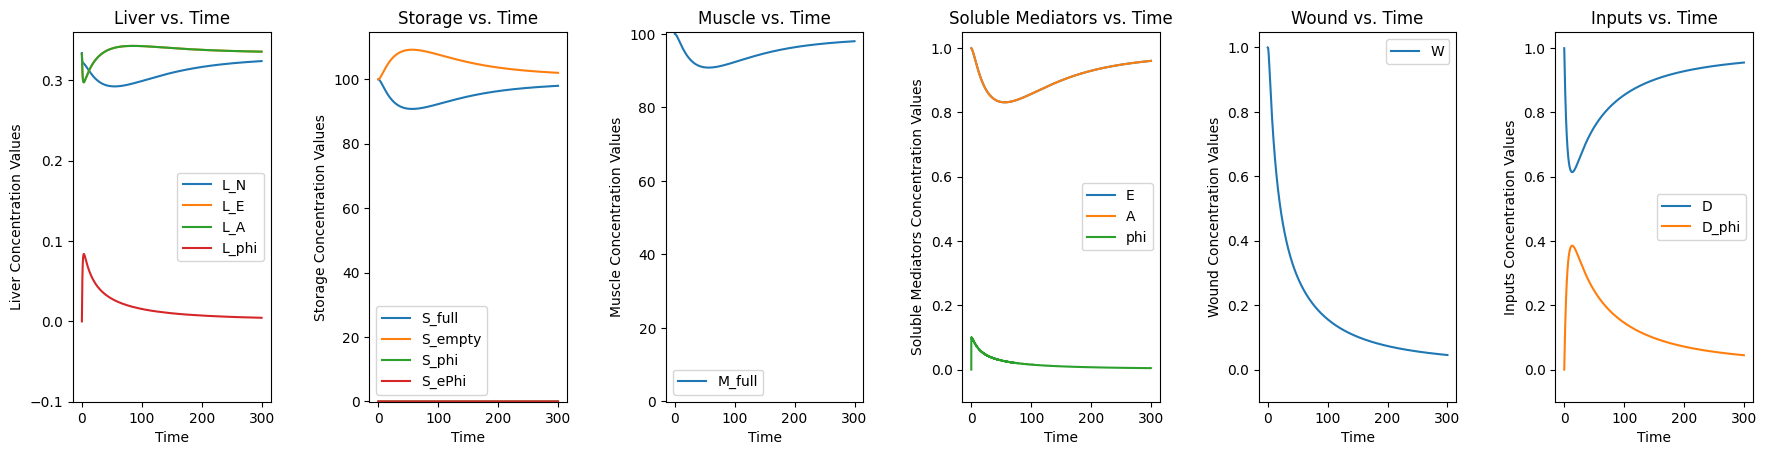

-0.9740335947610247
Final value of W: 0.04503096117849466
-0.8934341581051994
Final value of W: 0.03690055045466227
-0.8182391218077416
Final value of W: 0.03142662292696321
-0.754526724019955
Final value of W: 0.027542688421641218
-0.7019414313989405
Final value of W: 0.02465984134989093


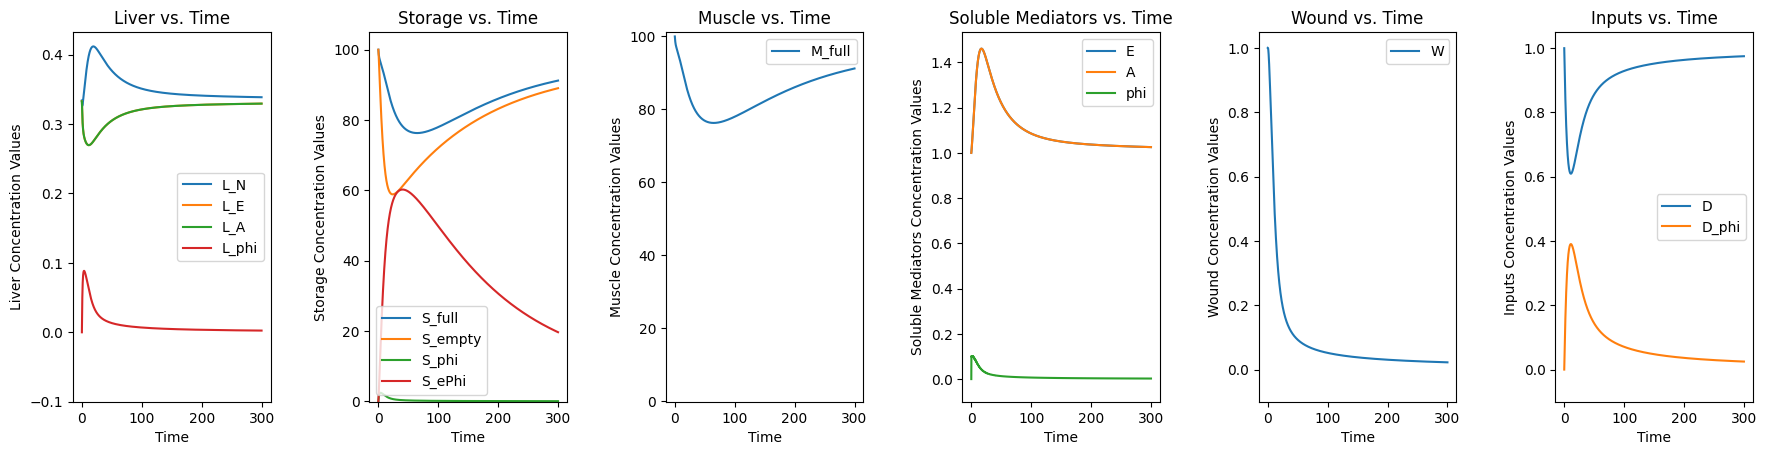

-0.6586709057717544
Final value of W: 0.02243760211489845
-0.6229237740794437
Final value of W: 0.020669548784559125
-0.593224899840181
Final value of W: 0.01922477991722107
-0.5684209431691419
Final value of W: 0.018016749194526272
-0.5476246274763834
Final value of W: 0.01698593881384167


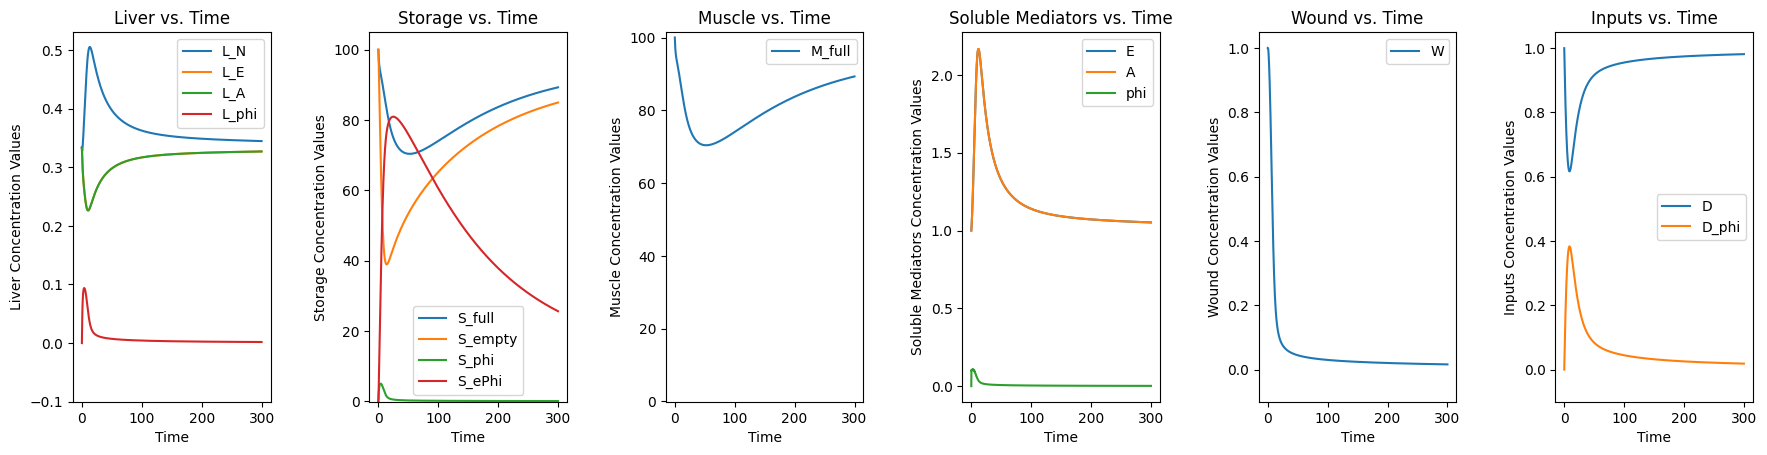

-0.5301542736717547
Final value of W: 0.01608979482380292
-0.5154829916345495
Final value of W: 0.01529661603413633
-0.5031965774461497
Final value of W: 0.01458166801035394
-0.492960199546849
Final value of W: 0.013924585985802089
-0.48448928297136395
Final value of W: 0.013307546656826125


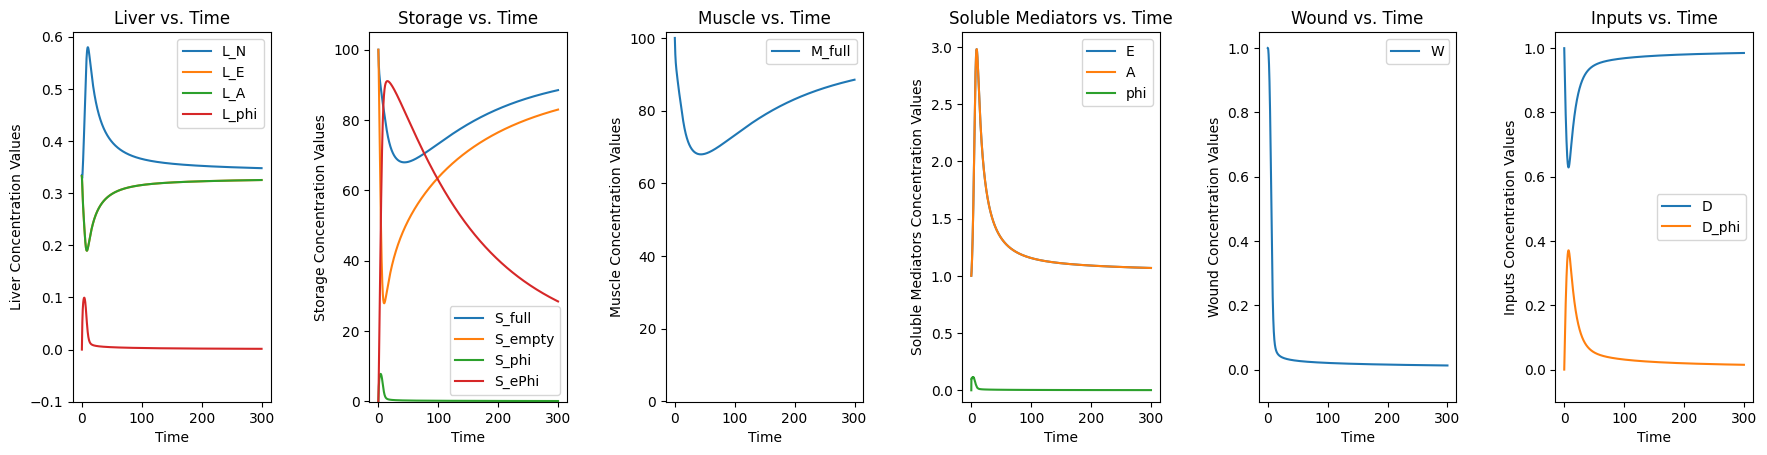

-0.4775249922180062
Final value of W: 0.012713924210641773
-0.47181354575046336
Final value of W: 0.01212730013965526
-0.4670907500457575
Final value of W: 0.011530825021388224
-0.46307445305185113
Final value of W: 0.010907063186089763
-0.4594669729735397
Final value of W: 0.010238586490734206


In [4]:
initWound = 1

diet = 1

midwoundValsVsTime = []

midrxnFlask = ReactionFlask(['W', 'D', 'D_phi', 'L_N', 'L_E', 'L_A', 'L_phi', 'S_full', 'S_empty', 'S_phi', 'S_ePhi', 'M_full', 'M_empty', 'M_phi', 'M_ePhi', 'E', 'A', 'phi', 'pI'], components = {"Liver" : ['L_N', 'L_E', 'L_A', 'L_phi'], "Storage" : ['S_full', 'S_empty', 'S_phi', 'S_ePhi'], "Muscle" : ['M_full'], "Soluble Mediators" : ['E', 'A', 'phi'], "Wound" : ['W'], "Inputs" : ['D', 'D_phi']})

midrxnFlask.setInitialCondition([initWound, diet, 0, 0.334, 0.333, 0.333, 0, 100, 100, 0, 0, 100, 100, 0, 0, 1, 1, 0, 0])

midSimulationOutputs = []

midrxnFlask.addReaction("Reaction 1: L_N -> L_A", 1, reactantsDict = {'L_N' : 1}, productsDict = {'L_A' : 1})

#
midrxnFlask.addReaction("Reaction 2: L_A + A -> L_N", 1, reactantsDict = {'L_A' : 1, 'A' : 1}, productsDict = {'L_N' : 1, 'A': 1})

#
midrxnFlask.addReaction("Reaction 3: L_A + E -> L_A + A", 1, reactantsDict = {'L_A' : 1, 'E' : 1}, productsDict = {'L_A' : 1, 'A' : 1})

#
midrxnFlask.addReaction("Reaction 4: L_E + A -> L_E + E", 1, reactantsDict = {'L_E' : 1, 'A' : 1}, productsDict = {'L_E' : 1, 'E' : 1})

#
midrxnFlask.addReaction("Reaction 5: L_N -> L_E", 1, reactantsDict = {'L_N' : 1}, productsDict = {'L_E' : 1})

#
midrxnFlask.addReaction("Reaction 6: L_E + E -> L_N", 1, reactantsDict = {'L_E' : 1, 'E' : 1}, productsDict = {'L_N' : 1, 'E' : 1})

#
midrxnFlask.addReaction("Reaction 7: D -> D + A", 1, reactantsDict = {'D' : 1}, productsDict = {'D' : 1, 'A' : 1})

#
midrxnFlask.addReaction("Reaction 8: D -> D + E", 1, reactantsDict = {'D' : 1}, productsDict = {'D' : 1, 'E' : 1})

#
midrxnFlask.addReaction("Reaction 9a: M_full + A -> M_full", 0.005, reactantsDict = {'M_full' : 1, 'A' : 1}, productsDict = {'M_full' : 1})

#
midrxnFlask.addReaction("Reaction 10a: M_full + E -> M_full", 0.005, reactantsDict = {'M_full' : 1, 'E' : 1}, productsDict = {'M_full' : 1})

#
midrxnFlask.addReaction("Reaction 9b: S_full + A -> S_full", 0.005, reactantsDict = {'S_full' : 1, 'A' : 1}, productsDict = {'S_full' : 1})

#
midrxnFlask.addReaction("Reaction 10b: S_full + E -> S_full", 0.005, reactantsDict = {'S_full' : 1, 'E' : 1}, productsDict = {'S_full' : 1})

#
midrxnFlask.addReaction("Reaction 11: S_full -> S_empty + jE", 1, reactantsDict = {'S_full' : 1}, productsDict = {'S_empty' : 1, 'E' : 1})

#
midrxnFlask.addReaction("Reaction 12: S_empty + jE -> S_full", 1, reactantsDict = {'S_empty' : 1, 'E' : 1}, productsDict = {'S_full' : 1})

#
midrxnFlask.addReaction("Reaction 15: S_phi -> S_ePhi + jE", 1, reactantsDict = {'S_phi' : 1}, productsDict = {'S_ePhi' : 1, 'E' : 1})

#
midrxnFlask.addReaction("Reaction 16: S_ePhi -> S_empty", 0.01, reactantsDict = {'S_ePhi' : 1}, productsDict = {'S_empty' : 1})

#
midrxnFlask.addReaction("Reaction 17: S_phi -> S_full", 0.01, reactantsDict = {'S_phi' : 1}, productsDict = {'S_full' : 1})

#
midrxnFlask.addReaction("Reaction 19: L_N + h * phi -> L_phi", 1, reactantsDict = {'L_N' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

#
midrxnFlask.addReaction("Reaction 20: L_phi -> L_N", 1, reactantsDict = {'L_phi' : 1}, productsDict = {'L_N' : 1})

#
midrxnFlask.addReaction("Reaction 21: L_phi + A + E -> L_phi + pI", 1, reactantsDict = {'L_phi' : 1, 'A' : 1, 'E' : 1}, productsDict = {'L_phi' : 1, 'pI' : 1})

#
midrxnFlask.addReaction("Reaction 22: pI -> naught", 1, reactantsDict = {'pI' : 1}, productsDict = {})

#
midrxnFlask.addReaction("Reaction 23: W -> W + phi", inflammationParameters[1], reactantsDict = {'W' : 1}, productsDict = {'W' : 1, 'phi' : 1})

#
midrxnFlask.addReaction("Reaction 24: W + pI -> naught", 1, reactantsDict = {'W' : 1, 'pI' : 1}, productsDict = {})

#
midrxnFlask.addReaction("Reaction 25: L_A + phi -> L_phi", 1, reactantsDict = {'L_A' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

#
midrxnFlask.addReaction("Reaction 26: L_E + phi -> L_phi", 1, reactantsDict = {'L_E' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

#
midrxnFlask.addReaction("Reaction 27: M_full -> M_empty + hA", 1, reactantsDict = {'M_full' : 1}, productsDict = {'M_empty' : 1, 'A' : 1})

#
midrxnFlask.addReaction("Reaction 28: M_empty + hA -> M_full", 1, reactantsDict = {'M_empty' : 1, 'A' : 1}, productsDict = {'M_full' : 1})

#
midrxnFlask.addReaction("Reaction 31: M_phi -> M_ePhi + hA", 1, reactantsDict = {'M_phi' : 1}, productsDict = {'M_ePhi' : 1, 'A' : 1})

#
midrxnFlask.addReaction("Reaction 32: M_ePhi -> M_empty", 0.01, reactantsDict = {'M_ePhi' : 1}, productsDict = {'M_empty' : 1})

#
midrxnFlask.addReaction("Reaction 33: M_phi -> M_full", 0.01, reactantsDict = {'M_phi' : 1}, productsDict = {'M_full' : 1})

#
midrxnFlask.addReaction("Reaction 34: D + phi -> D_phi + phi", 1, reactantsDict = {'D' : 1, 'phi' : 1}, productsDict = {'D_phi' : 1, 'phi' : 1})

#
midrxnFlask.addReaction("Reaction 35: D_phi -> D", 0.1, reactantsDict = {'D_phi': 1}, productsDict = {'D' : 1})



#
#This allows S_full to continue acting as an inflammation sink without changing state
midrxnFlask.addReaction("Reaction 13a: S_full + g * phi -> S_phi", 1, reactantsDict = {'S_full' : 1, 'phi' : 1}, productsDict = {'S_phi' : 1})
midrxnFlask.addReaction("Reaction 13b: S_full + g * phi -> S_full", 0, reactantsDict = {'S_full' : 1, 'phi' : 1}, productsDict = {'S_full' : 1})


#This allows S_empty to continue acting as an inflammation sink without changing state
midrxnFlask.addReaction("Reaction 14a: S_empty + g * phi -> S_ePhi", 1, reactantsDict = {'S_empty' : 1, 'phi' : 1}, productsDict = {'S_ePhi' : 1})
midrxnFlask.addReaction("Reaction 14b: S_empty + g * phi -> S_empty", 0, reactantsDict = {'S_empty' : 1, 'phi' : 1}, productsDict = {'S_empty' : 1})


#This allows M_full to continue acting as an inflammation sink while not changing state
midrxnFlask.addReaction("Reaction 29a: M_full + g * phi -> M_phi" , 1, reactantsDict = {'M_full' : 1, 'phi' : 1}, productsDict = {'M_phi' : 1})
midrxnFlask.addReaction("Reaction 29b: M_full + g * phi -> M_full" , 0, reactantsDict = {'M_full' : 1, 'phi' : 1}, productsDict = {'M_full' : 1})


#This allows M_empty to continue acting as an inflammation sink while not changing state
midrxnFlask.addReaction("Reaction 30a: M_empty + g * phi -> M_ePhi" , 1, reactantsDict = {'M_empty' : 1, 'phi' : 1}, productsDict = {'M_ePhi' : 1})
midrxnFlask.addReaction("Reaction 30b: M_empty + g * phi -> M_empty", 0, reactantsDict = {'M_empty' : 1, 'phi' : 1}, productsDict = {'M_empty' : 1})

for k in range(numPointsToTest):

    fractionIMW = (1 / (numPointsToTest - 1)) * k

    midrxnFlask.modifyReaction("Reaction 13a: S_full + g * phi -> S_phi", newRxnRate = fractionIMW)
    midrxnFlask.modifyReaction("Reaction 13b: S_full + g * phi -> S_full", newRxnRate = 1 - fractionIMW)


    #This allows S_empty to continue acting as an inflammation sink without changing state
    midrxnFlask.modifyReaction("Reaction 14a: S_empty + g * phi -> S_ePhi", newRxnRate = fractionIMW)
    midrxnFlask.modifyReaction("Reaction 14b: S_empty + g * phi -> S_empty", newRxnRate = 1 - fractionIMW)


    #This allows M_full to continue acting as an inflammation sink while not changing state
    midrxnFlask.modifyReaction("Reaction 29a: M_full + g * phi -> M_phi" , newRxnRate = fractionIMW)
    midrxnFlask.modifyReaction("Reaction 29b: M_full + g * phi -> M_full" , newRxnRate = 1 - fractionIMW)


    #This allows M_empty to continue acting as an inflammation sink while not changing state
    midrxnFlask.modifyReaction("Reaction 30a: M_empty + g * phi -> M_ePhi" ,newRxnRate = fractionIMW)
    midrxnFlask.modifyReaction("Reaction 30b: M_empty + g * phi -> M_empty", newRxnRate = 1 - fractionIMW)

    reactionDerivative1 = rxnFlask.reactionDeriv(0, [initWound, diet, 0, 0.334, 0.333, 0.333, 0, 100, 100, 0, 0, 100, 100, 0, 0, 1, 1, 0, 0])

    midrxnFlask.runSystem(300)

    if(k % 5 == 0):
        midrxnFlask.plotSystem(widthSpacing = 0.5, rightEdgeOfPlots = 2.75)

    timeValues = midrxnFlask.latestSimulationOutput["t"]

    localWeightDropValues = (46 * 2 - midrxnFlask.latestSimulationOutput["y"][7] - midrxnFlask.latestSimulationOutput["y"][11])

    print(np.max(localWeightDropValues) / (46 * 2))

    #print(rxnFlask.latestSimulationOutput["t"])

    print(f"Final value of W: {midrxnFlask.getFinalValueOfSpecies('W')}")

    midrxnFlask.resetInitialCondition()

    midSimulationOutputs.append(midrxnFlask.latestSimulationOutput)

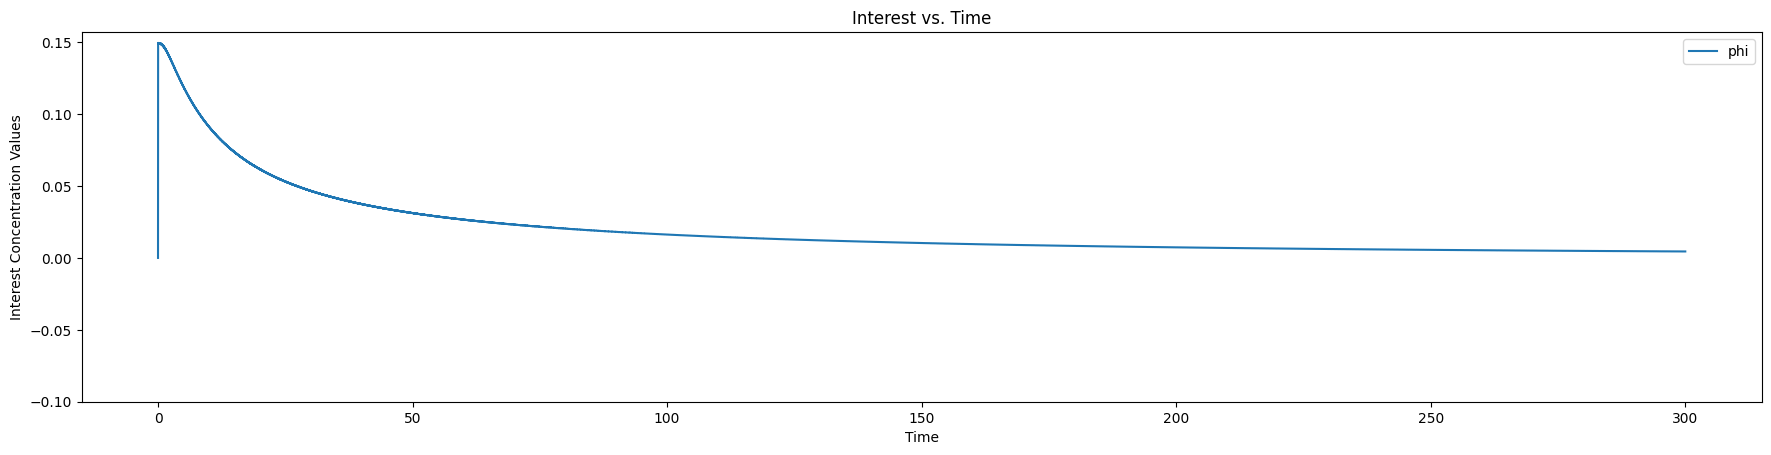

-0.9446622745257338
Final value of W: 0.030062308479258382
-0.8580792881531639
Final value of W: 0.023966693750767105
-0.7821194966679461
Final value of W: 0.020157480858055573
-0.7209350157582783
Final value of W: 0.017573226077796208
-0.6724926831663803
Final value of W: 0.01570372609340323


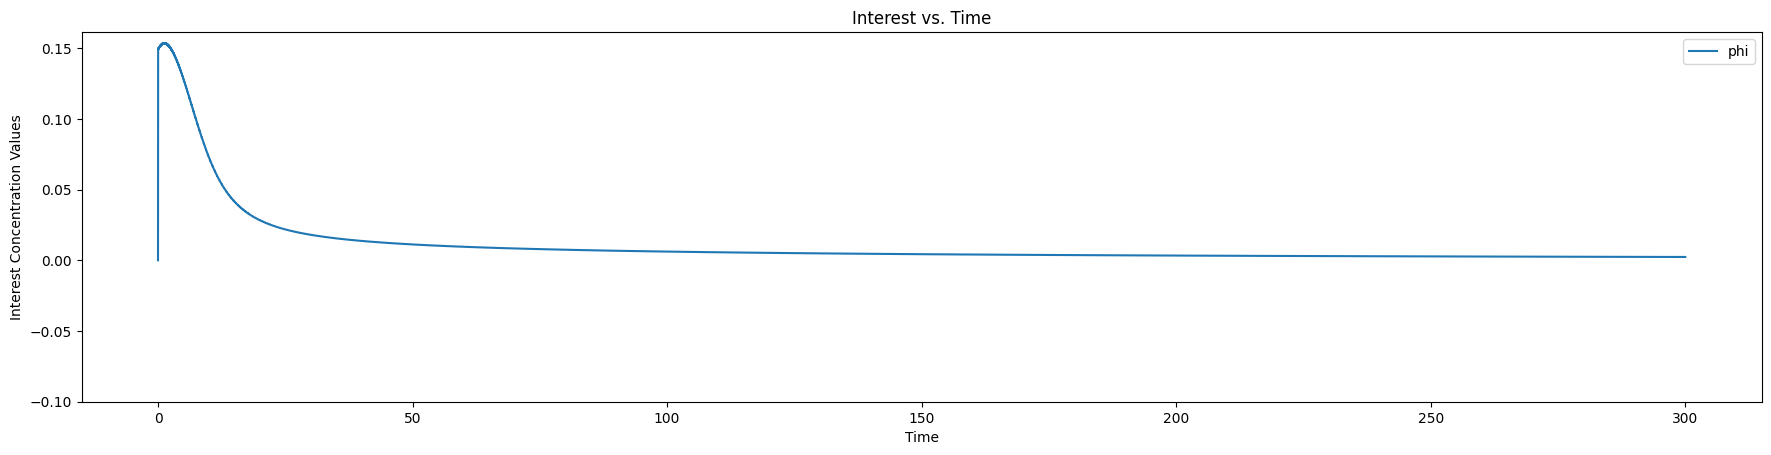

-0.6340263481492991
Final value of W: 0.014280954132824828
-0.6032732402725551
Final value of W: 0.013152393036327875
-0.5785543821295404
Final value of W: 0.012224627182615083
-0.5586453729033822
Final value of W: 0.011436010879435906
-0.5426357973522041
Final value of W: 0.010742233316668182


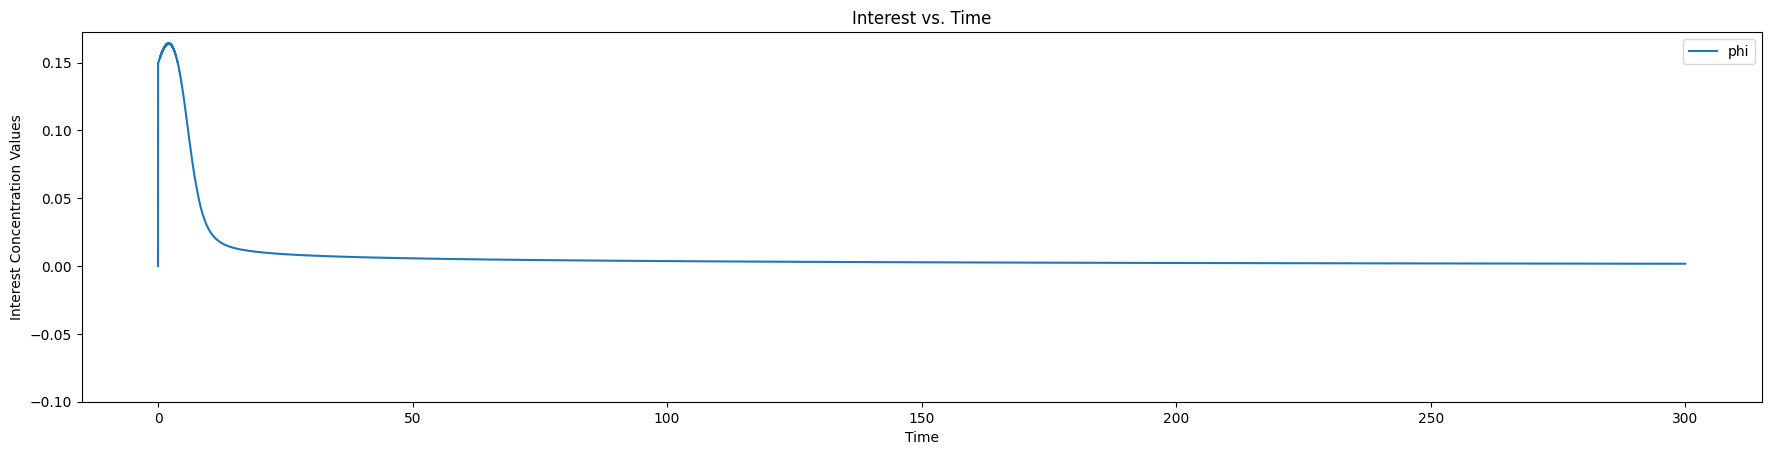

-0.5298083811512686
Final value of W: 0.010107943159832154
-0.5195362591615051
Final value of W: 0.009501391489698014
-0.5111998821826905
Final value of W: 0.008890846391035738
-0.5041342560843399
Final value of W: 0.008242734871753029
-0.4976264874961155
Final value of W: 0.007522678452217768


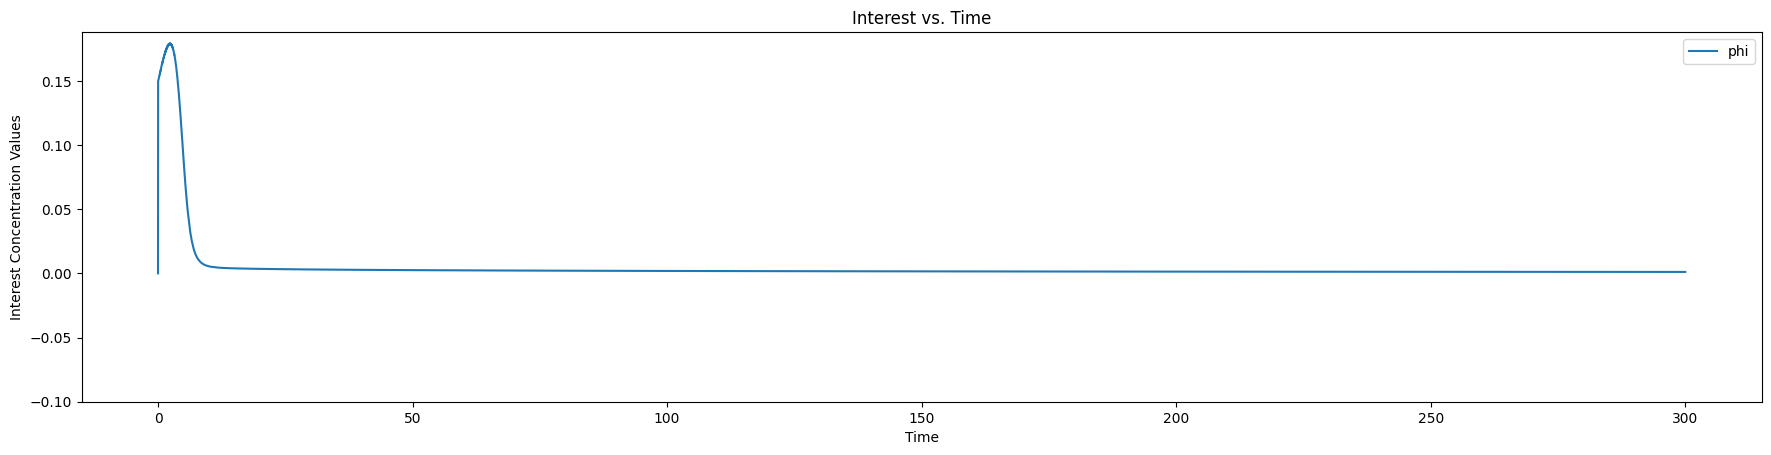

-0.4909706246142865
Final value of W: 0.006701643085932426
-0.48355631185186587
Final value of W: 0.005768721749392139
-0.474947709748109
Final value of W: 0.004746900929066936
-0.46491768936148964
Final value of W: 0.003699663382315459
-0.45343353568935085
Final value of W: 0.002715590518981307


In [ ]:
initWound = 1

diet = 1

highwoundValsVsTime = []

highrxnFlask = ReactionFlask(['W', 'D', 'D_phi', 'L_N', 'L_E', 'L_A', 'L_phi', 'S_full', 'S_empty', 'S_phi', 'S_ePhi', 'M_full', 'M_empty', 'M_phi', 'M_ePhi', 'E', 'A', 'phi', 'pI'], components = {"Liver" : ['L_N', 'L_E', 'L_A', 'L_phi'], "Storage" : ['S_full', 'S_empty', 'S_phi', 'S_ePhi'], "Muscle" : ['M_full'], "Soluble Mediators" : ['E', 'A', 'phi'], "Wound" : ['W'], "Inputs" : ['D', 'D_phi']})

highrxnFlask.setInitialCondition([initWound, diet, 0, 0.334, 0.333, 0.333, 0, 100, 100, 0, 0, 100, 100, 0, 0, 1, 1, 0, 0])

highSimulationOutputs = []

highrxnFlask.addReaction("Reaction 1: L_N -> L_A", 1, reactantsDict = {'L_N' : 1}, productsDict = {'L_A' : 1})

#
highrxnFlask.addReaction("Reaction 2: L_A + A -> L_N", 1, reactantsDict = {'L_A' : 1, 'A' : 1}, productsDict = {'L_N' : 1, 'A': 1})

#
highrxnFlask.addReaction("Reaction 3: L_A + E -> L_A + A", 1, reactantsDict = {'L_A' : 1, 'E' : 1}, productsDict = {'L_A' : 1, 'A' : 1})

#
highrxnFlask.addReaction("Reaction 4: L_E + A -> L_E + E", 1, reactantsDict = {'L_E' : 1, 'A' : 1}, productsDict = {'L_E' : 1, 'E' : 1})

#
highrxnFlask.addReaction("Reaction 5: L_N -> L_E", 1, reactantsDict = {'L_N' : 1}, productsDict = {'L_E' : 1})

#
highrxnFlask.addReaction("Reaction 6: L_E + E -> L_N", 1, reactantsDict = {'L_E' : 1, 'E' : 1}, productsDict = {'L_N' : 1, 'E' : 1})

#
highrxnFlask.addReaction("Reaction 7: D -> D + A", 1, reactantsDict = {'D' : 1}, productsDict = {'D' : 1, 'A' : 1})

#
highrxnFlask.addReaction("Reaction 8: D -> D + E", 1, reactantsDict = {'D' : 1}, productsDict = {'D' : 1, 'E' : 1})

#
highrxnFlask.addReaction("Reaction 9a: M_full + A -> M_full", 0.005, reactantsDict = {'M_full' : 1, 'A' : 1}, productsDict = {'M_full' : 1})

#
highrxnFlask.addReaction("Reaction 10a: M_full + E -> M_full", 0.005, reactantsDict = {'M_full' : 1, 'E' : 1}, productsDict = {'M_full' : 1})

#
highrxnFlask.addReaction("Reaction 9b: S_full + A -> S_full", 0.005, reactantsDict = {'S_full' : 1, 'A' : 1}, productsDict = {'S_full' : 1})

#
highrxnFlask.addReaction("Reaction 10b: S_full + E -> S_full", 0.005, reactantsDict = {'S_full' : 1, 'E' : 1}, productsDict = {'S_full' : 1})

#
highrxnFlask.addReaction("Reaction 11: S_full -> S_empty + jE", 1, reactantsDict = {'S_full' : 1}, productsDict = {'S_empty' : 1, 'E' : 1})

#
highrxnFlask.addReaction("Reaction 12: S_empty + jE -> S_full", 1, reactantsDict = {'S_empty' : 1, 'E' : 1}, productsDict = {'S_full' : 1})

#
highrxnFlask.addReaction("Reaction 15: S_phi -> S_ePhi + jE", 1, reactantsDict = {'S_phi' : 1}, productsDict = {'S_ePhi' : 1, 'E' : 1})

#
highrxnFlask.addReaction("Reaction 16: S_ePhi -> S_empty", 0.01, reactantsDict = {'S_ePhi' : 1}, productsDict = {'S_empty' : 1})

#
highrxnFlask.addReaction("Reaction 17: S_phi -> S_full", 0.01, reactantsDict = {'S_phi' : 1}, productsDict = {'S_full' : 1})

#
highrxnFlask.addReaction("Reaction 19: L_N + h * phi -> L_phi", 1, reactantsDict = {'L_N' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

#
highrxnFlask.addReaction("Reaction 20: L_phi -> L_N", 1, reactantsDict = {'L_phi' : 1}, productsDict = {'L_N' : 1})

#
highrxnFlask.addReaction("Reaction 21: L_phi + A + E -> L_phi + pI", 1, reactantsDict = {'L_phi' : 1, 'A' : 1, 'E' : 1}, productsDict = {'L_phi' : 1, 'pI' : 1})

#
highrxnFlask.addReaction("Reaction 22: pI -> naught", 1, reactantsDict = {'pI' : 1}, productsDict = {})

#
highrxnFlask.addReaction("Reaction 23: W -> W + phi", inflammationParameters[2], reactantsDict = {'W' : 1}, productsDict = {'W' : 1, 'phi' : 1})

#
highrxnFlask.addReaction("Reaction 24: W + pI -> naught", 1, reactantsDict = {'W' : 1, 'pI' : 1}, productsDict = {})

#
highrxnFlask.addReaction("Reaction 25: L_A + phi -> L_phi", 1, reactantsDict = {'L_A' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

#
highrxnFlask.addReaction("Reaction 26: L_E + phi -> L_phi", 1, reactantsDict = {'L_E' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

#
highrxnFlask.addReaction("Reaction 27: M_full -> M_empty + hA", 1, reactantsDict = {'M_full' : 1}, productsDict = {'M_empty' : 1, 'A' : 1})

#
highrxnFlask.addReaction("Reaction 28: M_empty + hA -> M_full", 1, reactantsDict = {'M_empty' : 1, 'A' : 1}, productsDict = {'M_full' : 1})

#
highrxnFlask.addReaction("Reaction 31: M_phi -> M_ePhi + hA", 1, reactantsDict = {'M_phi' : 1}, productsDict = {'M_ePhi' : 1, 'A' : 1})

#
highrxnFlask.addReaction("Reaction 32: M_ePhi -> M_empty", 0.01, reactantsDict = {'M_ePhi' : 1}, productsDict = {'M_empty' : 1})

#
highrxnFlask.addReaction("Reaction 33: M_phi -> M_full", 0.01, reactantsDict = {'M_phi' : 1}, productsDict = {'M_full' : 1})

#
highrxnFlask.addReaction("Reaction 34: D + phi -> D_phi + phi", 1, reactantsDict = {'D' : 1, 'phi' : 1}, productsDict = {'D_phi' : 1, 'phi' : 1})

#
highrxnFlask.addReaction("Reaction 35: D_phi -> D", 0.1, reactantsDict = {'D_phi': 1}, productsDict = {'D' : 1})



#
#This allows S_full to continue acting as an inflammation sink without changing state
highrxnFlask.addReaction("Reaction 13a: S_full + g * phi -> S_phi", 1, reactantsDict = {'S_full' : 1, 'phi' : 1}, productsDict = {'S_phi' : 1})
highrxnFlask.addReaction("Reaction 13b: S_full + g * phi -> S_full", 0, reactantsDict = {'S_full' : 1, 'phi' : 1}, productsDict = {'S_full' : 1})


#This allows S_empty to continue acting as an inflammation sink without changing state
highrxnFlask.addReaction("Reaction 14a: S_empty + g * phi -> S_ePhi", 1, reactantsDict = {'S_empty' : 1, 'phi' : 1}, productsDict = {'S_ePhi' : 1})
highrxnFlask.addReaction("Reaction 14b: S_empty + g * phi -> S_empty", 0, reactantsDict = {'S_empty' : 1, 'phi' : 1}, productsDict = {'S_empty' : 1})


#This allows M_full to continue acting as an inflammation sink while not changing state
highrxnFlask.addReaction("Reaction 29a: M_full + g * phi -> M_phi" , 1, reactantsDict = {'M_full' : 1, 'phi' : 1}, productsDict = {'M_phi' : 1})
highrxnFlask.addReaction("Reaction 29b: M_full + g * phi -> M_full" , 0, reactantsDict = {'M_full' : 1, 'phi' : 1}, productsDict = {'M_full' : 1})


#This allows M_empty to continue acting as an inflammation sink while not changing state
highrxnFlask.addReaction("Reaction 30a: M_empty + g * phi -> M_ePhi" , 1, reactantsDict = {'M_empty' : 1, 'phi' : 1}, productsDict = {'M_ePhi' : 1})
highrxnFlask.addReaction("Reaction 30b: M_empty + g * phi -> M_empty", 0, reactantsDict = {'M_empty' : 1, 'phi' : 1}, productsDict = {'M_empty' : 1})

for k in range(numPointsToTest):

    fractionIMW = (1 / (numPointsToTest - 1)) * k

    highrxnFlask.modifyReaction("Reaction 13a: S_full + g * phi -> S_phi", newRxnRate = fractionIMW)
    highrxnFlask.modifyReaction("Reaction 13b: S_full + g * phi -> S_full", newRxnRate = (1 - fractionIMW))


    #This allows S_empty to continue acting as an inflammation sink without changing state
    highrxnFlask.modifyReaction("Reaction 14a: S_empty + g * phi -> S_ePhi", newRxnRate = fractionIMW)
    highrxnFlask.modifyReaction("Reaction 14b: S_empty + g * phi -> S_empty", newRxnRate = (1 - fractionIMW))


    #This allows M_full to continue acting as an inflammation sink while not changing state
    highrxnFlask.modifyReaction("Reaction 29a: M_full + g * phi -> M_phi" , newRxnRate = fractionIMW)
    highrxnFlask.modifyReaction("Reaction 29b: M_full + g * phi -> M_full" , newRxnRate = (1 - fractionIMW))


    #This allows M_empty to continue acting as an inflammation sink while not changing state
    highrxnFlask.modifyReaction("Reaction 30a: M_empty + g * phi -> M_ePhi" ,newRxnRate = fractionIMW)
    highrxnFlask.modifyReaction("Reaction 30b: M_empty + g * phi -> M_empty", newRxnRate = (1 - fractionIMW))

    #reactionDerivative1 = rxnFlask.reactionDeriv(0, [initWound, diet, 0, 0.334, 0.333, 0.333, 0, 100, 100, 0, 0, 100, 100, 0, 0, 1, 1, 0, 0])

    highrxnFlask.runSystem(300)

    if k % 5 == 0:
        highrxnFlask.plotSystem(widthSpacing = 0.5, rightEdgeOfPlots = 2.75)

    timeValues = highrxnFlask.latestSimulationOutput["t"]

    localWeightDropValues = (46 * 2 - highrxnFlask.latestSimulationOutput["y"][7] - highrxnFlask.latestSimulationOutput["y"][11])

    print(np.max(localWeightDropValues) / (46 * 2))

    #print(rxnFlask.latestSimulationOutput["t"])

    print(f"Final value of W: {highrxnFlask.getFinalValueOfSpecies('W')}")

    highrxnFlask.resetInitialCondition()

    highSimulationOutputs.append(highrxnFlask.latestSimulationOutput)

In [6]:
#1. Get boolean mask of finalWoundValues, <= 10% of initWound
def calculateWoundHealingTime(timeValues, woundValues, threshold):
  #initWound = woundValues[0], correct?
  healedWound = np.where(woundValues <= threshold * woundValues[0])[0]
  try:
    healedWoundIndex = healedWound[0]
  except(IndexError):
    #This ensures that, if the wound never was healed to the threshold, it
    #automatically reports the longest time
    return timeValues[-1]

  healedWoundTime = timeValues[healedWoundIndex]
  return healedWoundTime


In [7]:
def riemannSum(timeValues, functionValues, side):
  #1. Define summing variable and begin loop
  areaSum = 0
  for k in range(len(timeValues) - 1):
    dt = timeValues[k + 1] - timeValues[k]

    if side == "left":
      height = functionValues[k]
    elif side == "right":
      height = functionValues[k + 1]
    else:
      print("You've made a mistake in entering the side that you would like to approximate the value of the function from. Valid choices are 'left' and 'right'")

    areaSum += height * dt

  return areaSum

In [8]:
def calculateMetricsOnSimulation(simulationOutput):
  timeValues = simulationOutput["t"]
  woundValues = simulationOutput["y"][0]
  fatValues = simulationOutput["y"][7]
  muscleValues = simulationOutput["y"][11]
  aminoAcidLevels = simulationOutput["y"][16]

  startingWeight = 100 * 2

  weightDropValues = startingWeight - (fatValues + muscleValues)
  weightDropValues = weightDropValues / startingWeight

  maxWeightDrop = np.max(weightDropValues)

  #When diet = 1, the steady state value of amino acid level will be 1
  aminoAcidDropValues = 1 - aminoAcidLevels

  maxAminoAcidDrop = np.max(aminoAcidDropValues)

  return (calculateWoundHealingTime(timeValues, woundValues, threshold = 0.1),
          riemannSum(timeValues, weightDropValues, "left"),
          maxWeightDrop,
          riemannSum(timeValues, aminoAcidDropValues, "left"),
          maxAminoAcidDrop)

In [9]:
woundHealingTimeValues = np.zeros((len([20, 40, 60]), numPointsToTest))
weightDropIntegralVals = np.zeros((len([20, 40, 60]), numPointsToTest))
maxWeightDropVals = np.zeros((len([20, 40, 60]), numPointsToTest))
aminoAcidDropIntegralVals = np.zeros((len([20, 40, 60]), numPointsToTest))
maxAminoAcidDropVals = np.zeros((len([20, 40, 60]), numPointsToTest))

for c in range(3):
  for k in range(numPointsToTest):
    simulationOutputObjects = [lowSimulationOutputs, midSimulationOutputs, highSimulationOutputs]
    simulationOutput = simulationOutputObjects[c][k]
    (woundHealingTimeValues[c][k],
      weightDropIntegralVals[c][k],
      maxWeightDropVals[c][k],
      aminoAcidDropIntegralVals[c][k],
      maxAminoAcidDropVals[c][k]) = calculateMetricsOnSimulation(simulationOutput)

print(maxWeightDropVals)

[[0.06814884 0.09904975 0.13051299 0.15932773 0.18483128 0.20716399
  0.22666401 0.2436961  0.25859952 0.27167311 0.28317347 0.29331827
  0.30229076 0.31024493 0.31730992 0.3235942  0.32918876 0.3341705
  0.33860416 0.3425448 ]
 [0.09194455 0.12902029 0.16361    0.19291771 0.21710694 0.23701138
  0.25345506 0.26711655 0.27852637 0.28809267 0.29612903 0.30287782
  0.30852957 0.31323831 0.31713493 0.3203385  0.32296577 0.32513825
  0.32698575 0.32864519]
 [0.10545535 0.14528353 0.18022503 0.20836989 0.23065337 0.24834788
  0.26249431 0.27386498 0.28302313 0.29038753 0.29628814 0.30101332
  0.30484805 0.30809824 0.31109182 0.31415351 0.3175641  0.32152405
  0.32613786 0.33142057]]


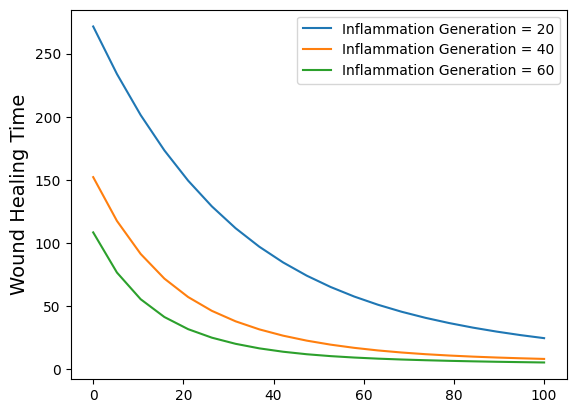

In [10]:
fractionIMWsTested = [100 * (1 / (numPointsToTest - 1)) * k for k in range(numPointsToTest)]

plt.plot(fractionIMWsTested, woundHealingTimeValues[0][:], label = f"Inflammation Generation = {inflammationParameters[0]}")
plt.plot(fractionIMWsTested, woundHealingTimeValues[1][:], label = f"Inflammation Generation = {inflammationParameters[1]}")
plt.plot(fractionIMWsTested, woundHealingTimeValues[2][:], label = f"Inflammation Generation = {inflammationParameters[2]}")

plt.legend()

plt.ylabel("Wound Healing Time", size = 14)

plt.savefig("FigureImages/Figure3Images/woundHealingTimeVsFractionIMW.png")

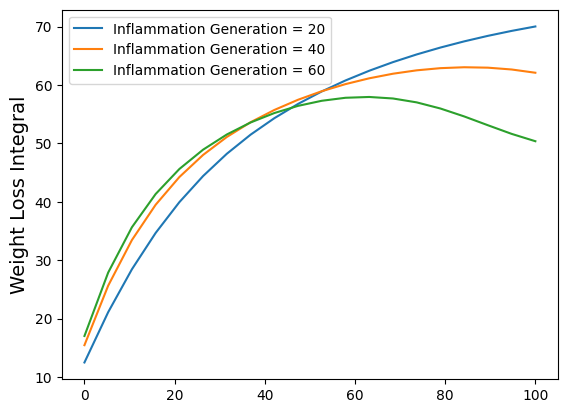

In [11]:
fractionIMWsTested = [100 * (1 / (numPointsToTest - 1)) * k for k in range(numPointsToTest)]

plt.plot(fractionIMWsTested, weightDropIntegralVals[0][:], label = f"Inflammation Generation = {inflammationParameters[0]}")
plt.plot(fractionIMWsTested, weightDropIntegralVals[1][:], label = f"Inflammation Generation = {inflammationParameters[1]}")
plt.plot(fractionIMWsTested, weightDropIntegralVals[2][:], label = f"Inflammation Generation = {inflammationParameters[2]}")

plt.legend()

plt.ylabel("Weight Loss Integral", size = 14)

plt.savefig("FigureImages/Figure3Images/weightLossVsPercentIMW.png")

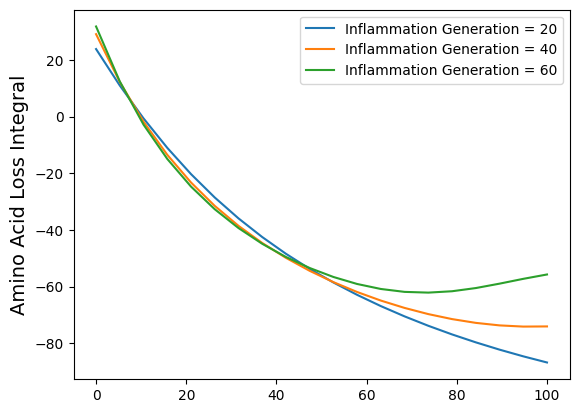

In [12]:
fractionIMWsTested = [100 * (1 / (numPointsToTest - 1)) * k for k in range(numPointsToTest)]

plt.plot(fractionIMWsTested, aminoAcidDropIntegralVals[0][:], label = f"Inflammation Generation = {inflammationParameters[0]}")
plt.plot(fractionIMWsTested, aminoAcidDropIntegralVals[1][:], label = f"Inflammation Generation = {inflammationParameters[1]}")
plt.plot(fractionIMWsTested, aminoAcidDropIntegralVals[2][:], label = f"Inflammation Generation = {inflammationParameters[2]}")

plt.legend()

plt.ylabel("Amino Acid Loss Integral", size = 14)

plt.savefig("FigureImages/Figure3Images/aminoAcidLossVsPercentIMW.png")

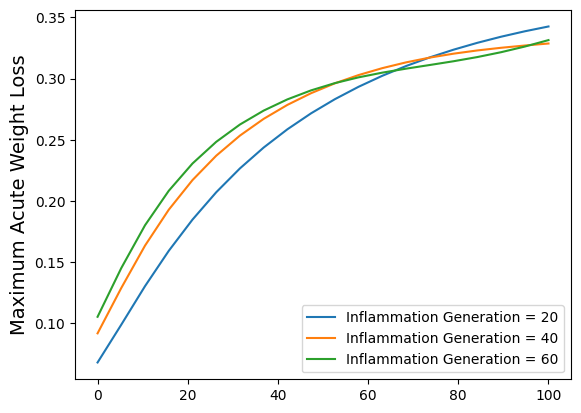

In [13]:
fractionIMWsTested = [100 * (1 / (numPointsToTest - 1)) * k for k in range(numPointsToTest)]

plt.plot(fractionIMWsTested, maxWeightDropVals[0][:], label = f"Inflammation Generation = {inflammationParameters[0]}")
plt.plot(fractionIMWsTested, maxWeightDropVals[1][:], label = f"Inflammation Generation = {inflammationParameters[1]}")
plt.plot(fractionIMWsTested, maxWeightDropVals[2][:], label = f"Inflammation Generation = {inflammationParameters[2]}")

plt.legend()

plt.ylabel("Maximum Acute Weight Loss", size = 14)

plt.savefig("FigureImages/Figure3Images/maxWeightDropVsPercentIMW.png")